### [1] Importing Dependencies

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc
from scipy.integrate import solve_ivp
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, ConstantKernel as C
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import random

In [2]:
np.random.seed(42)
random.seed(42)

### Dataset

In [3]:
# ===================== User Settings =====================

Mr = 10.0 # robot mass
Tsim = 40.0 # simulation time in [s] #it was 60s
Ts = 0.00005 # smapling time in [s]
num_samples = 220 # number of samples in paramter space: 220
train_fraction = 0.80
peak_metric = 'max'  # 'max' or 'maxabs'



param_names = ['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']

# Parameter ranges used for sampling

lb = np.array([100, 100, 10, 0.1, 0.1, 1e-4, 3, 0.1, 0.3])
ub = np.array([5000, 5000, 100, 0.3, 1.1, 1e-2, 10, 0.2, 0.5])

In [4]:
print(len(param_names))
print(lb.shape)
print(ub.shape)

9
(9,)
(9,)


### Sampling

In [5]:
sampler = qmc.LatinHypercube(d=len(lb), seed=42) # this creates the sampler of dimension d
sample = sampler.random(n=num_samples) #this actually sample randomly within 0,1
X = qmc.scale(sample, lb, ub) # this scale the 0,1 result to our values

In [6]:
print(X.shape)
#print(sample) # this hould be 0 and 1 and in between
print(X) # our values

(220, 9)
[[4.02503462e+03 6.24770435e+02 4.76942099e+01 ... 3.26214555e+00
  1.32824516e-01 4.05338079e-01]
 [4.49996868e+03 2.69765041e+03 3.17117780e+01 ... 3.50186059e+00
  1.73838825e-01 4.11760166e-01]
 [1.21747549e+03 3.31547657e+03 5.95989641e+01 ... 8.95705143e+00
  1.88547891e-01 4.36848435e-01]
 ...
 [2.17202733e+03 3.24823087e+02 3.41483458e+01 ... 9.59865092e+00
  1.64266029e-01 4.50529769e-01]
 [4.65317261e+03 1.25476118e+03 5.75610032e+01 ... 3.55769418e+00
  1.66586441e-01 4.24261623e-01]
 [3.86477115e+03 3.82548950e+03 5.15763229e+01 ... 8.09273646e+00
  1.36939024e-01 4.13440688e-01]]


### Dynamical system

In [7]:
# To simulate the system we need:
# - a function that describes the dynamic, "system dynamics"
# - the solver for the dynamical system, "simulate_peak_joint_position"
def chirp_signal(t, f0, f1, Tsim, A):
    """Generates a linear chirp signal."""
    k = (f1 - f0) / Tsim
    phi = 2 * np.pi * (f0 * t + 0.5 * k * t**2)
    return A * np.cos(phi)

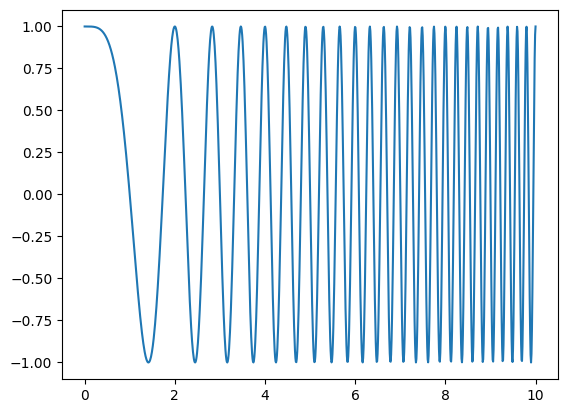

In [8]:
t_try = np.linspace(0,10,1000)
Chirp  =  chirp_signal(t_try,0,5,10,1)

Chirp.shape

plt.figure()
plt.plot(t_try,Chirp)
plt.show()

In [9]:
#chekcing what dict() does
p = dict(zip(param_names, X[150,:])) # create the dictionary
p

{'Kb': np.float64(1775.0260102897903),
 'Kr': np.float64(1573.6144881585615),
 'Mb': np.float64(41.383655717674515),
 'hb': np.float64(0.14154200307417278),
 'hr': np.float64(0.9323893897439327),
 'f0': np.float64(0.003608921334001242),
 'f1': np.float64(8.45616726315286),
 'A_sin': np.float64(0.18933469285696297),
 'x_r_start': np.float64(0.38937261202765594)}

In [10]:
def system_dynamics(t, state, p, Mr):
    """Two-mass spring-damper system ODE."""
    xb, v_xb, xr, v_xr = state # state vector organised as [xb, v_xb, xr, v_xr]

    # xr is relative to the base

    # Extract params: WATCH OUT "p" is defined after as a dictionary

    Kb, Kr, Mb, hb, hr = p['Kb'], p['Kr'], p['Mb'], p['hb'], p['hr']
    A_sin, f0, f1 = p['A_sin'], p['f0'], p['f1']
    xr_start = p['x_r_start']

    # Active robot command (chirp position): that is compute the chirp signal
    x_cmd = xr_start + chirp_signal(t, f0, f1, Tsim, A_sin) # watch out for the sign

    cb = 2 * hb * Mb * np.sqrt(Kb / Mb)
    cr = 2 * hr * Mr * np.sqrt(Kr / Mr)

    # Equations of motion
    # Note: Assuming robot is controlled to follow x_cmd relative to base

    # For a surrogate model, we simulate the coupled ODE:
    a_b = (-Kr*x_cmd+Kr*xr+cr*v_xr-cb*v_xb-Kb*xb)/Mb

    # Simplified robot tracking dynamics
    a_r = (-Kr*xr-cr*v_xr+Kr*x_cmd)/Mr-a_b
    # it returns the left end side of the equation

    return [v_xb, a_b, v_xr, a_r]

In [11]:
def simulate_peak_joint_position(params_vec):

    # INPUT: "params_vec", it's the vector of parameters (1,9)

    p = dict(zip(param_names, params_vec)) # create the dictionary
    t_eval = np.arange(0, Tsim, Ts) # this is useful to state which points to take during the integration algorithm
    y0 = [0, 0, p['x_r_start'], 0] # initial condition of the state

    sol = solve_ivp(system_dynamics, [0, Tsim], y0, t_eval=t_eval, args=(p, Mr), method='RK45')


    # Output y = xb + xr
    # RECALL we organized the state as [xb, v_xb, xr, v_xr]
    # xb is sol.y[0], xr is sol.y[2]
    y_signal = sol.y[0] + sol.y[2] # this is the whole time history

    # we take just the max of the time history

    if peak_metric == 'maxabs':
        return np.max(np.abs(y_signal)), y_signal

    return np.max(y_signal), y_signal, sol.y[0], sol.y[2]

In [12]:
# simulate for 1 set of parameters

max_disp, y_signal, _, _ = simulate_peak_joint_position(X[0,:])
y_signal = np.array(y_signal)
y_signal.shape

(800000,)

[4.02503462e+03 6.24770435e+02 4.76942099e+01 1.27547847e-01
 6.04117376e-01 4.55609699e-03 3.26214555e+00 1.32824516e-01
 4.05338079e-01]
(800000,)


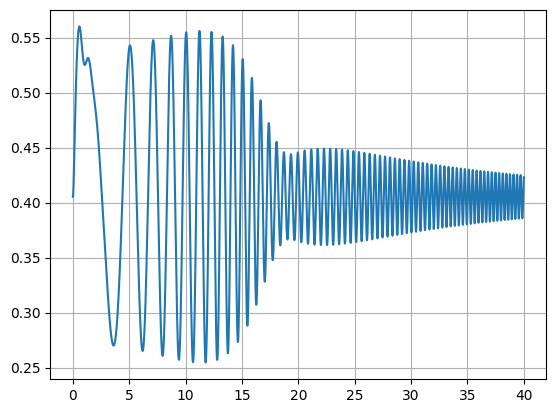

In [13]:
# plot
y_signal.shape
print(X[0,:])
t = np.linspace(0,Tsim,int(Tsim/Ts))

print(t.shape)

plt.figure()
plt.plot(t,y_signal)
plt.grid()
plt.show()

In [14]:
print(len(X))
print(X[0,:])
print(X[1,:])

220
[4.02503462e+03 6.24770435e+02 4.76942099e+01 1.27547847e-01
 6.04117376e-01 4.55609699e-03 3.26214555e+00 1.32824516e-01
 4.05338079e-01]
[4.49996868e+03 2.69765041e+03 3.17117780e+01 1.05778304e-01
 1.04171472e+00 6.65046361e-04 3.50186059e+00 1.73838825e-01
 4.11760166e-01]


In [15]:


Y_MAT = []
Y_max = []

for i in range(len(X)):
    max_sig, y_signalv1,_,_ = simulate_peak_joint_position(X[i,:])
    Y_MAT.append(y_signalv1)
    Y_max.append(max_sig)

print(np.array(Y_MAT).shape)
print(np.array(Y_max).shape)

Y_MAT = np.vstack(Y_MAT)
Y_max = np.array(Y_max) # Opzionale: trasforma anche i picchi in array

print(Y_MAT.shape)
print(Y_max.shape)

(220, 800000)
(220,)
(220, 800000)
(220,)


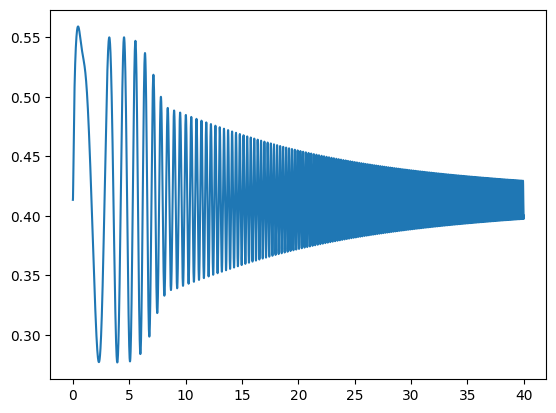

In [16]:
# checking dimension and reshaping

t = np.linspace(0,Tsim,int(Tsim/Ts))


plt.figure()
plt.plot(t,Y_MAT[219,:])
plt.show()

In [17]:
# Build the dataset
results_df = pd.DataFrame(X, columns=param_names)   # 1. Create the DataFrame using the X matrix and parameter names

results_df['peak_y'] = Y_max  # 2. Add the peak_y column (the target variable Y)

print(results_df)

              Kb           Kr         Mb        hb        hr        f0  \
0    4025.034615   624.770435  47.694210  0.127548  0.604117  0.004556   
1    4499.968677  2697.650408  31.711778  0.105778  1.041715  0.000665   
2    1217.475488  3315.476566  59.598964  0.279678  0.827406  0.005685   
3     744.933462   742.472643  74.766025  0.212959  0.954693  0.009355   
4    3460.288112  1047.132027  42.225355  0.197573  0.129831  0.002268   
..           ...          ...        ...       ...       ...       ...   
215   298.164960  4098.510864  40.025879  0.264322  0.145261  0.000315   
216  2598.456199  3888.018797  54.099448  0.126428  1.054464  0.009958   
217  2172.027329   324.823087  34.148346  0.188591  1.072372  0.009197   
218  4653.172611  1254.761178  57.561003  0.126295  1.055774  0.008657   
219  3864.771150  3825.489500  51.576323  0.288023  1.021729  0.005254   

           f1     A_sin  x_r_start    peak_y  
0    3.262146  0.132825   0.405338  0.560178  
1    3.501861  0.

### Dataset splitting

In [18]:
from sklearn.model_selection import train_test_split

# X is your (220, 9) array, Y is your (220,) or (220, 1) array
# train_size=0.80 means 80% for training, 20% for testing
# random_state=42 acts like MATLAB's 'rng(42)', ensuring the split is the same every time you run it

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y_max,
    train_size=0.80,
    random_state=42,
    shuffle=True
)

print(f"Training samples: {len(X_train)}")  # Should be 176
print(f"Testing samples: {len(X_test)}")    # Should be 44

Training samples: 176
Testing samples: 44


### Kernel choice

In [19]:
inputSpan = ub - lb

In [20]:

# FIRST BENCHMARK

from sklearn.preprocessing import StandardScaler,MinMaxScaler

# Initialize the scaler

scaler_x = StandardScaler()

# "fit" compute mu (the MEAN), std (the STANDARD DEVIATION)
# "transform" compute the x_scaled = (x - mu)/std
# Scale the train and test set

X_train_s = scaler_x.fit_transform(X_train)
X_test_s = scaler_x.transform(X_test)

print(f"The MEAN is: {scaler_x.mean_}")
print(f"The STD is: {scaler_x.scale_}")

# scale also the bounds

# ub_2d = np.array(ub).reshape(1, -1)
# lb_2d = np.array(lb).reshape(1, -1)

# use the scaler fitted on the X
# ub_scaled = scaler_x.transform(ub_2d)
# lb_scaled = scaler_x.transform(lb_2d)

# Compute the new scaled range

# input_span_scaled = ub_scaled - lb_scaled


The MEAN is: [2.53954860e+03 2.62391406e+03 5.47355322e+01 2.00420339e-01
 6.04600578e-01 4.97818098e-03 6.57866401e+00 1.49249013e-01
 4.01879613e-01]
The STD is: [1.41939430e+03 1.39599631e+03 2.58925161e+01 5.81256910e-02
 2.86605168e-01 2.89943057e-03 2.02785643e+00 2.88994054e-02
 5.82204868e-02]


In [21]:
input_span_scaled_new = inputSpan / scaler_x.scale_
print(input_span_scaled_new.shape)
X_train_s

(9,)


array([[ 0.12231139, -1.05513701,  0.56473901, ..., -1.27994389,
        -1.0223669 , -1.06215226],
       [-0.25892824, -1.64691766, -0.79510181, ...,  1.48925085,
         0.51963062,  0.83561919],
       [-1.24555731,  1.35042577, -1.02386272, ..., -0.15696373,
        -1.13257794,  1.57129858],
       ...,
       [-1.05769426,  1.29915671,  0.88534069, ...,  1.34627948,
        -0.18740187,  1.65786695],
       [-0.77370412, -1.34163924, -0.05896153, ..., -0.28311188,
        -0.6030622 ,  1.13820886],
       [ 0.15950281,  1.51774857, -0.67070014, ..., -1.1083429 ,
         0.7612443 ,  0.85524586]], shape=(176, 9))

In [22]:
print(lb/scaler_x.scale_)
print(ub/scaler_x.scale_)

[0.07045259 0.07163343 0.38621198 1.72040965 0.34891206 0.03448953
 1.47939467 3.46027881 5.15282534]
[3.52262933 3.58167137 3.86211983 5.16122896 3.83803268 3.44895308
 4.93131557 6.92055762 8.58804224]


In [23]:
short_ls = (0.15 * input_span_scaled_new).flatten()
medium_ls = (0.50 * input_span_scaled_new).flatten()
long_ls   = (1.00 * input_span_scaled_new).flatten()

shortLS  = 0.15 * inputSpan
mediumLS = 0.50 * inputSpan
longLS   = 1.00 * inputSpan

print(f'The lengthscale magnitude for the SHORT_scaled are: {short_ls}')
print(f'The lengthscale magnitude for the MEDIUM_scaled are: {medium_ls}')
print(f'The lengthscale magnitude for the LONG_scaled are: {long_ls}')

print(f'The lengthscale magnitude for the SHORT are: {shortLS}')
print(f'The lengthscale magnitude for the MEDIUM are: {mediumLS}')
print(f'The lengthscale magnitude for the LONG are: {longLS}')

The lengthscale magnitude for the SHORT_scaled are: [0.51782651 0.52650569 0.52138618 0.5161229  0.52336809 0.51216953
 0.51778813 0.51904182 0.51528253]
The lengthscale magnitude for the MEDIUM_scaled are: [1.72608837 1.75501897 1.73795393 1.72040965 1.74456031 1.70723177
 1.72596045 1.7301394  1.71760845]
The lengthscale magnitude for the LONG_scaled are: [3.45217675 3.51003794 3.47590785 3.44081931 3.48912062 3.41446355
 3.4519209  3.46027881 3.4352169 ]
The lengthscale magnitude for the SHORT are: [7.350e+02 7.350e+02 1.350e+01 3.000e-02 1.500e-01 1.485e-03 1.050e+00
 1.500e-02 3.000e-02]
The lengthscale magnitude for the MEDIUM are: [2.45e+03 2.45e+03 4.50e+01 1.00e-01 5.00e-01 4.95e-03 3.50e+00 5.00e-02
 1.00e-01]
The lengthscale magnitude for the LONG are: [4.9e+03 4.9e+03 9.0e+01 2.0e-01 1.0e+00 9.9e-03 7.0e+00 1.0e-01 2.0e-01]


In [24]:
from sklearn.gaussian_process.kernels import Matern, RBF, RationalQuadratic, ConstantKernel as C, WhiteKernel as W

# Define the kernel to test:

# we are defining the whole kernel as:   Constant*Base_kernel(length_scale, nu) + noise where the constant is modeling the sigma^2 of our space

Sigma_squared = np.var(Y_train)
yStd = np.std(Y_train) # in m

kernels_to_test = {
    
    "Matern_32_short": C((0.5*yStd)**2)* Matern(length_scale = short_ls, nu=1.5) + W(noise_level= (0.02*yStd)**2),
    "Matern_32_medium": C((1.0*yStd)**2) * Matern(length_scale = medium_ls, nu=1.5) + W(noise_level=(0.05*yStd)**2),
    "Matern_32_long": C((1.5*yStd)**2) * Matern(length_scale = long_ls, nu=1.5) + W(noise_level=(0.10*yStd)**2),
    "Matern_52_medium": C((1.0*yStd)**2) * Matern(length_scale = medium_ls, nu=2.5) + W(noise_level=(0.05*yStd)**2),
    "RBF": C((0.5*yStd)**2) * RBF(length_scale = medium_ls) + W(noise_level=(0.05*yStd)**2),
    "Exponential_short": C((1.0*yStd)**2) * Matern(length_scale = short_ls , nu=0.5) + W(noise_level=(0.02*yStd)**2),
    "Exponential_medium": C((1.0*yStd)**2) * Matern(length_scale = medium_ls, nu=0.5) + W(noise_level=(0.05*yStd)**2),
}

In [25]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np

results = {}
benchmark_data = []

for name, kernel in kernels_to_test.items():

    # initialize the kernel 
    gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, normalize_y=True, random_state= 42) # restart optimizer
    
    # Training (usa i tuoi dati XTrain, YTrain)
    gpr.fit(X_train_s, Y_train)
    

    # Validazione del train set
    y_train_pred = gpr.predict(X_train_s)
    r2_train = r2_score(Y_train, y_train_pred)
    rmse_train = np.sqrt(mean_squared_error(Y_train, y_train_pred)) 
    mae_train = mean_absolute_error(Y_train, y_train_pred)


    # Validazione del test set
    y_test_pred = gpr.predict(X_test_s)
    rmse_test = np.sqrt(mean_squared_error(Y_test, y_test_pred))
    r2_test = r2_score(Y_test, y_test_pred)
    mae_test = mean_absolute_error(Y_test, y_test_pred)


    # Extraction of hyperparameters
    params = gpr.kernel_.get_params()

    # other quantities

    ls_opt = params.get('k1__k2__length_scale', "N/A")
    sigma_opt = params.get('k1__k1__constant_value', "N/A") # da controllare
    noise_opt = params.get('k2__noise_level', "N/A")
    

    # saving the results
    results[name] = {
        "RMSE_test": rmse_test, 
        "RMSE_train": rmse_train, 
        "MAE_test": mae_test,
        "MAE_test": mae_train,
        "R2_test": r2_test, 
        "R2_train": r2_train,
        "optimized_ls": ls_opt,
        "optimized_sigma": sigma_opt,
        "optimized_noise": noise_opt,
        "Model": gpr
          }
    
    # creating the table also ROW by ROW

    row = {
        "Name": name,
        "TrainRMSE": rmse_train,
        "TrainMAE": mae_train,
        "TrainR2": r2_train,
        "TestRMSE": rmse_test,
        "TestMAE": mae_test,
        "TestR2": r2_test,
        "Opt_Noise": params.get('k2__noise_level', "N/A"),
        "Status": "OK"
    }
    
    # append the rows one below the other

    benchmark_data.append(row)
    print(f"Completed: {name}")

    print(f"--- {name} ---")
    print(f"  R2   | Train: {r2_train:.8f}  vs  Test: {r2_test:.8f}")
    print(f"  RMSE | Train: {rmse_train:.8f}  vs  Test: {rmse_test:.8f}")
    print(f"  MAE | Train: {mae_train:.8f}  vs  Test: {mae_test:.8f}")
    print(f"Length Scale Optimized: {ls_opt}")
    print("-" * 30)

c:\Users\utente1\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\gaussian_process\kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Completed: Matern_32_short
--- Matern_32_short ---
  R2   | Train: 1.00000000  vs  Test: 0.95848260
  RMSE | Train: 0.00000638  vs  Test: 0.01871308
  MAE | Train: 0.00000451  vs  Test: 0.01297580
Length Scale Optimized: [ 103.62247193   97.16183299   41.30728275 1537.37818383   17.92317388
 2698.58905527 3911.47033386  119.38990277  282.43090669]
------------------------------
Completed: Matern_32_medium
--- Matern_32_medium ---
  R2   | Train: 0.00767378  vs  Test: -0.00084268
  RMSE | Train: 0.09130505  vs  Test: 0.09187834
  MAE | Train: 0.07024177  vs  Test: 0.07405103
Length Scale Optimized: [4.21912938e+01 1.30951585e-02 1.58737747e+00 2.93158704e+00
 7.05577227e-04 4.96416579e+04 5.64063806e+02 2.48307259e+04
 8.87714889e+03]
------------------------------
Completed: Matern_32_long
--- Matern_32_long ---
  R2   | Train: 0.00767378  vs  Test: -0.00084268
  RMSE | Train: 0.09130505  vs  Test: 0.09187834
  MAE | Train: 0.07024177  vs  Test: 0.07405103
Length Scale Optimized: [4.21

c:\Users\utente1\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\gaussian_process\kernels.py:450: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\utente1\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\gaussian_process\kernels.py:450: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\utente1\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\gaussian_process\kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better val

Completed: Exponential_short
--- Exponential_short ---
  R2   | Train: 1.00000000  vs  Test: 0.91716245
  RMSE | Train: 0.00000265  vs  Test: 0.02643284
  MAE | Train: 0.00000170  vs  Test: 0.01815968
Length Scale Optimized: [1.24300403e+03 5.02406384e+02 2.15621249e+02 2.01280297e+03
 4.59258819e+01 1.00000000e+05 1.00000000e+05 1.90278589e+02
 1.66801225e+02]
------------------------------
Completed: Exponential_medium
--- Exponential_medium ---
  R2   | Train: 0.00767378  vs  Test: -0.00084270
  RMSE | Train: 0.09130505  vs  Test: 0.09187834
  MAE | Train: 0.07024177  vs  Test: 0.07405104
Length Scale Optimized: [4.21912938e+01 1.30951586e-02 1.58737747e+00 2.93158704e+00
 7.05577230e-04 4.96416579e+04 5.64063806e+02 2.48307259e+04
 8.87714889e+03]
------------------------------


In [26]:
# --- MAKING THE TABLE ---
df_results = pd.DataFrame(benchmark_data)

# Set the table ordered following the decrease of R2 index
df_results = df_results.sort_values(by="TestR2", ascending=False).reset_index(drop=True)

# Visualization
print("\nValidation benchmark:")
print(df_results.to_string(index=True))


Validation benchmark:
                 Name  TrainRMSE  TrainMAE   TrainR2  TestRMSE   TestMAE    TestR2  Opt_Noise Status
0     Matern_32_short   0.000006  0.000005  1.000000  0.018713  0.012976  0.958483   0.000010     OK
1   Exponential_short   0.000003  0.000002  1.000000  0.026433  0.018160  0.917162   0.000010     OK
2                 RBF   0.091634  0.070495  0.000513  0.091878  0.074051 -0.000843   0.999744     OK
3    Matern_52_medium   0.091305  0.070242  0.007674  0.091878  0.074051 -0.000843   0.996156     OK
4    Matern_32_medium   0.091305  0.070242  0.007674  0.091878  0.074051 -0.000843   0.996156     OK
5      Matern_32_long   0.091305  0.070242  0.007674  0.091878  0.074051 -0.000843   0.996156     OK
6  Exponential_medium   0.091305  0.070242  0.007674  0.091878  0.074051 -0.000843   0.996156     OK


In [27]:
# Identify the first object in the dataframe
best_model_name = df_results.iloc[0]['Name']

# Get the kernel
best_gpr = results[best_model_name]['Model']

# Get the best kernel
kernel_opt = best_gpr.kernel_

# Extract the kernel apram using get_params()
# NOTA: I nomi delle chiavi (k1, k2) dipendono dalla struttura del kernel che hai definito
params = kernel_opt.get_params()

In [28]:


# Extraction of the parameters
optimized_ls = params.get('k1__k2__length_scale') # La lunghezza di scala (vettore di 9 elementi)
optimized_sigma_sq = params.get('k1__k1__constant_value') # Il valore di Constant (sigma^2)
optimized_noise = params.get('k2__noise_level') # Il livello di rumore (WhiteKernel)

print(f"Modello migliore: {best_model_name}")
print(f"--- Parametri Ottimizzati ---")
print(f"Sigma^2 (Constant): {optimized_sigma_sq}")
print(f"Rumore (Noise Level): {optimized_noise}")
print(f"Length Scales (ARD):\n{optimized_ls}")

Modello migliore: Matern_32_short
--- Parametri Ottimizzati ---
Sigma^2 (Constant): 1445.8183575614169
Rumore (Noise Level): 9.999999999999997e-06
Length Scales (ARD):
[ 103.62247193   97.16183299   41.30728275 1537.37818383   17.92317388
 2698.58905527 3911.47033386  119.38990277  282.43090669]


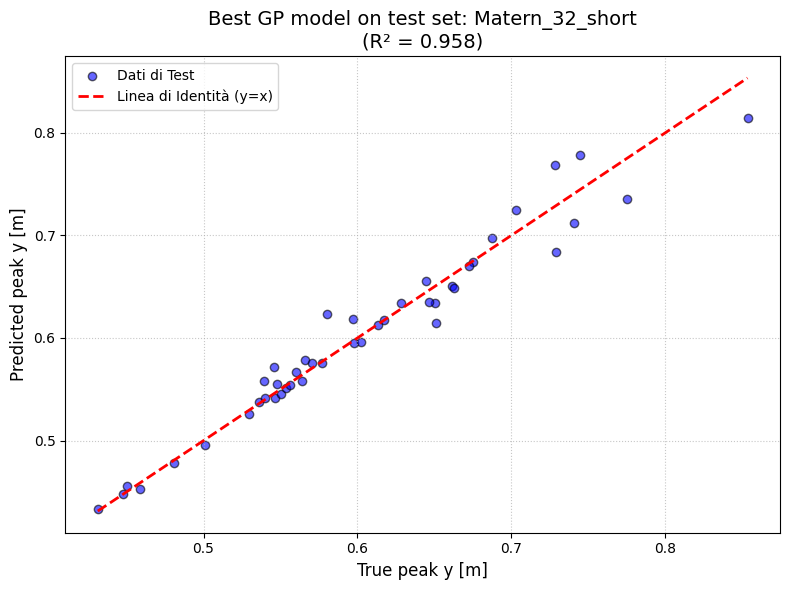

In [29]:
# get the best model

Y_test_pred = best_gpr.predict(X_test_s)
r2_test_best = df_results.iloc[0]['TestR2']

# plot of the kernel quantites

plt.figure(figsize=(8, 6))

# Scatter plot of the identity line of the true vs predicted
plt.scatter(Y_test, Y_test_pred, color='blue', alpha=0.6, edgecolors='k', label='Dati di Test')

# Add the identity line
# Calcoliamo i limiti basandoci sui valori minimi e massimi presenti
all_values = np.concatenate([Y_test, Y_test_pred])
l_min, l_max = all_values.min(), all_values.max()
plt.plot([l_min, l_max], [l_min, l_max], color='red', linestyle='--', linewidth=2, label='Linea di Identità (y=x)')

#  labels and size
plt.title(f'Best GP model on test set: {best_model_name}\n(R² = {r2_test_best:.3f})', fontsize=14)
plt.xlabel('True peak y [m]', fontsize=12)
plt.ylabel('Predicted peak y [m]', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()

# Show graph
plt.tight_layout()
plt.show()

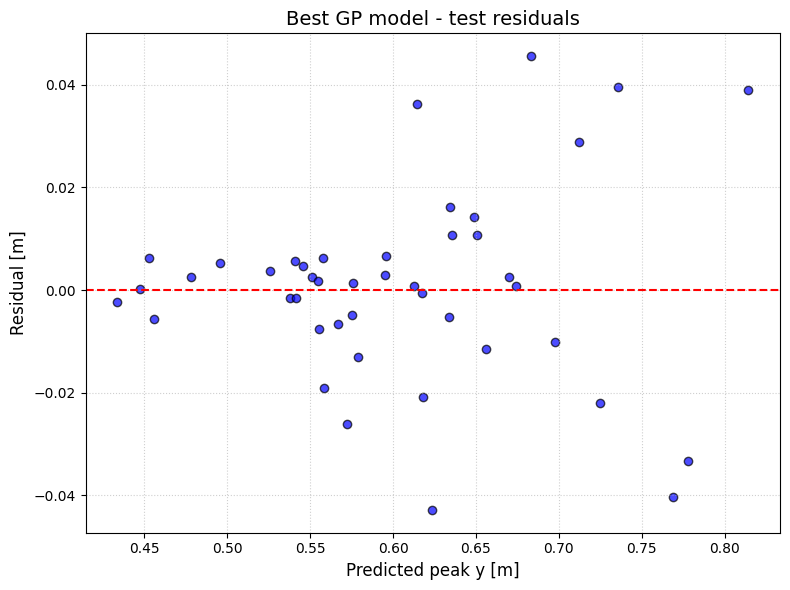

In [30]:
# 1. Calcolo delle predizioni e dei residui
# Assicurati che Y_test_pred e Y_test siano array o liste di uguale dimensione
Y_test_pred = best_gpr.predict(X_test_s)
residuals = Y_test - Y_test_pred

# 2. Creazione della figura
plt.figure(figsize=(8, 6))

# 3. Scatter plot dei residui
# 'edgecolors' aggiunge il contorno ai punti per richiamare lo stile 'filled' di MATLAB
plt.scatter(Y_test_pred, residuals, s=36, color='blue', alpha=0.7, edgecolors='k')

# 4. Aggiunta della linea orizzontale sullo zero (riferimento ideale)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)

# 5. Formattazione e labels
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlabel('Predicted peak y [m]', fontsize=12)
plt.ylabel('Residual [m]', fontsize=12)
plt.title('Best GP model - test residuals', fontsize=14)

# 6. Visualizzazione
plt.tight_layout()
plt.show()

[0.08529751 0.09096925 0.21397533 0.00574923 0.49314588 0.00327532
 0.0022597  0.07403255 0.03129523]
[0.00965042 0.01029211 0.02420881 0.00065046 0.05579369 0.00037056
 0.00025566 0.00837592 0.00354069]


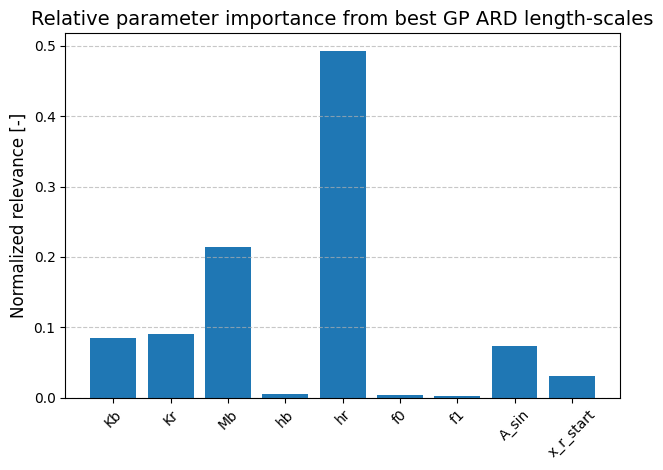

In [31]:
relevance_scores = 1.0 / np.maximum(optimized_ls, 1e-9)
normalized_relevance = relevance_scores / np.sum(relevance_scores)


print(normalized_relevance)
print(relevance_scores)


# show the figure

plt.bar(param_names, normalized_relevance)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylabel('Normalized relevance [-]', fontsize=12)
plt.title('Relative parameter importance from best GP ARD length-scales', fontsize=14)
plt.xticks(rotation=45) # Rotate the ticks
# Visualization
plt.tight_layout()
plt.show()

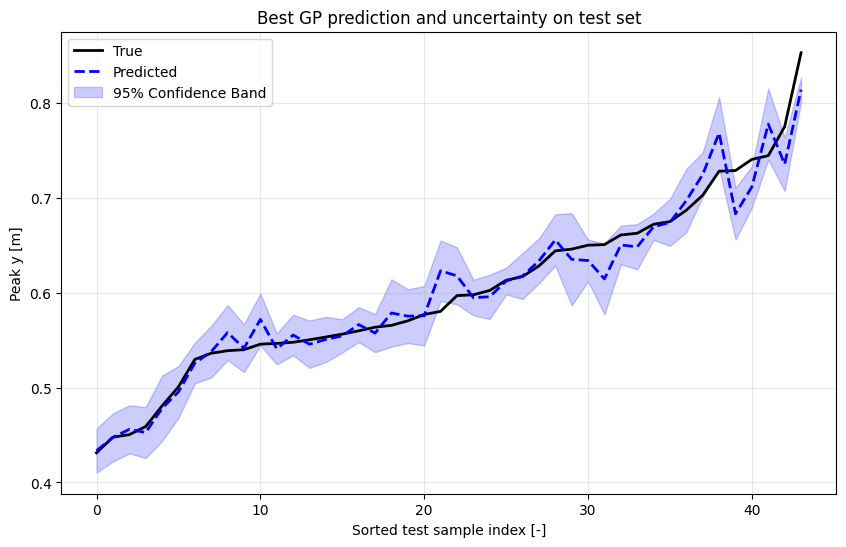

In [32]:
# Obtain the prediction and std
Y_pred, Y_std = best_gpr.predict(X_test_s, return_std=True)

# Order the data of Y_test, we order because Y_test are casually ordered. we order them to make th graph
sort_idx = np.argsort(Y_test)
Y_test_sorted = Y_test[sort_idx]
Y_pred_sorted = Y_pred[sort_idx]
Y_std_sorted = Y_std[sort_idx]

# Plot
plt.figure(figsize=(10, 6))

# Real data and predicted one
plt.plot(Y_test_sorted, label='True', linewidth=2, color='black')
plt.plot(Y_pred_sorted, label='Predicted', linewidth=2, color='blue', linestyle='--')

# Confidence bands (95% -> 1.96 * std)
plt.fill_between(range(len(Y_test_sorted)), 
                 Y_pred_sorted - 1.96 * Y_std_sorted, 
                 Y_pred_sorted + 1.96 * Y_std_sorted, 
                 color='blue', alpha=0.2, label='95% Confidence Band')

# label and size
plt.xlabel('Sorted test sample index [-]')
plt.ylabel('Peak y [m]')
plt.title('Best GP prediction and uncertainty on test set')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

In [33]:
results

{'Matern_32_short': {'RMSE_test': np.float64(0.01871308171112471),
  'RMSE_train': np.float64(6.382274847773693e-06),
  'MAE_test': 4.507993753936649e-06,
  'R2_test': 0.9584826000874304,
  'R2_train': 0.9999999951514053,
  'optimized_ls': array([ 103.62247193,   97.16183299,   41.30728275, 1537.37818383,
           17.92317388, 2698.58905527, 3911.47033386,  119.38990277,
          282.43090669]),
  'optimized_sigma': np.float64(1445.8183575614169),
  'optimized_noise': np.float64(9.999999999999997e-06),
  'Model': GaussianProcessRegressor(kernel=0.0458**2 * Matern(length_scale=[0.518, 0.527, 0.521, 0.516, 0.523, 0.512, 0.518, 0.519, 0.515], nu=1.5) + WhiteKernel(noise_level=3.36e-06),
                           n_restarts_optimizer=10, normalize_y=True,
                           random_state=42)},
 'Matern_32_medium': {'RMSE_test': np.float64(0.09187834196474509),
  'RMSE_train': np.float64(0.09130504834083868),
  'MAE_test': 0.07024177092830257,
  'R2_test': -0.0008426821792857364,

In [34]:

# Extraction of the data

nomi_modelli = list(results.keys())
rmse_test_set = [results[n]['RMSE_test'] for n in nomi_modelli]
mae_test_set = [results[n]['MAE_test'] for n in nomi_modelli]
r2_test_set = [results[n]['R2_test'] for n in nomi_modelli]


print(rmse_test_set)
print(mae_test_set)
print(r2_test_set)

[np.float64(0.01871308171112471), np.float64(0.09187834196474509), np.float64(0.09187834196474509), np.float64(0.09187834195011002), np.float64(0.09187834194843644), np.float64(0.026432842225141653), np.float64(0.09187834264359748)]
[4.507993753936649e-06, 0.07024177092830257, 0.07024177092830257, 0.0702417709283152, 0.07049476109330371, 1.7003271390727725e-06, 0.07024177091780454]
[0.9584826000874304, -0.0008426821792857364, -0.0008426821792857364, -0.0008426818604423403, -0.0008426818239815059, 0.9171624497801568, -0.0008426969689399044]


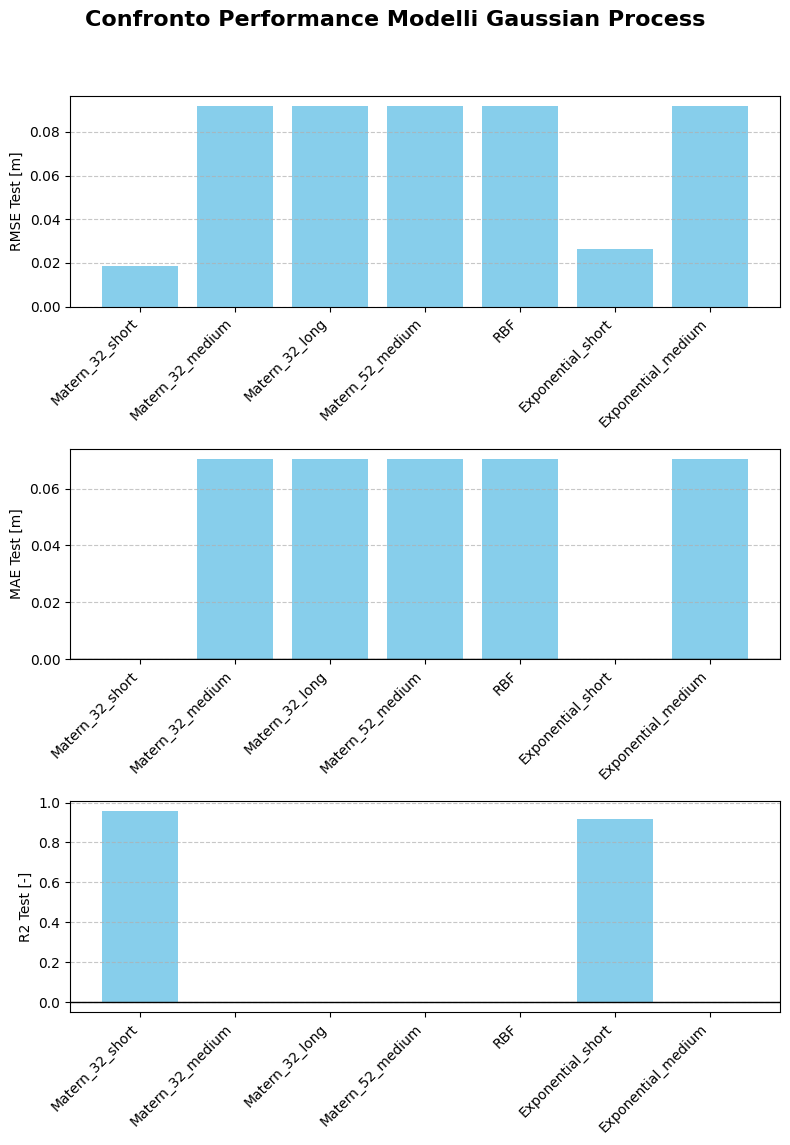

In [35]:
fig, axs = plt.subplots(3, 1, figsize=(8, 12))
# --- Global titles ---
fig.suptitle('Confronto Performance Modelli Gaussian Process', fontsize=16, fontweight='bold', y=0.98)

axs[0].bar(nomi_modelli, rmse_test_set, color='skyblue')
axs[0].set_ylabel('RMSE Test [m]')
axs[0].grid(axis='y', linestyle='--', alpha=0.7)



axs[1].bar(nomi_modelli, mae_test_set, color='skyblue')
axs[1].set_ylabel('MAE Test [m]')
axs[1].grid(axis='y', linestyle='--', alpha=0.7)
axs[1].axhline(0, color='black', linewidth=1)



axs[2].bar(nomi_modelli, r2_test_set, color='skyblue')
axs[2].set_ylabel('R2 Test [-]')
axs[2].grid(axis='y', linestyle='--', alpha=0.7)
axs[2].axhline(0, color='black', linewidth=1)


# this is for rotating the labels on x-axis
for ax in axs:
    # Rotate the ticks
    ax.tick_params(axis='x', rotation=45)
    # Make them aligned
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# Use this to avoid the overlapping of the labels with the plots
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) 

plt.show()

# [3] Finding the Optimal Parameters using Bayesian Optimization

### [3.1] Bayesian Optimization Loop


In [36]:
from sklearn.preprocessing import MinMaxScaler
from skopt.space import Real

# Inizializza il MinMaxScaler
scaler_x_min = MinMaxScaler()

# Adatta lo scaler sui dati originali (X è la matrice campionata con LHC)
scaler_x_min.fit(X) 

# Definisci il search_space scalato: 
# Ogni parametro ora vive tra 0.0 e 1.0

search_space_s = [
    Real(0.0, 1.0, name=name)
    for name in param_names
]

In [37]:
search_space_s

[Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity'),
 Real(low=0.0, high=1.0, prior='uniform', transform='identity')]

In [38]:
def loss_function(params_list):
    """
    This function is called by gp_minimize.
    params_list: a list of 9 values chosen by the optimizer.
    """

    # 1. Converti in array 2D per lo scaler
    params_vec_scaled = np.array(params_list).reshape(1, -1)
    
    # 2. RIPORTA AI VALORI FISICI ORIGINALI
    params_vec_phys = scaler_x_min.inverse_transform(params_vec_scaled).flatten()

    # Convert the list to a numpy array (which your simulation expects)
    # params_vec = np.array(params_list)

    # 2. Run your existing simulation
    # We only need the max_disp (the scalar), not the whole time signal
    max_disp, _, _,_ = simulate_peak_joint_position(params_vec_phys)

    # 3. Return the value.
    # NOTE: gp_minimize MINIMIZES.
    # If you want to MAXIMIZE peak joint position, return -max_disp
    return -max_disp

In [39]:
X_test_s = scaler_x_min.transform(X) 


max_disp = loss_function(X_test_s[1,:])
print(max_disp)
print(X_test_s[1,:])
params_vec_phys = scaler_x.inverse_transform(X_test_s)
print(params_vec_phys[1,:])

_, yprova,_,_ = simulate_peak_joint_position(X_test[1,:])

-0.6055357092972509
[0.89861289 0.52908232 0.2402881  0.02633214 0.94450226 0.05422843
 0.07055924 0.74061934 0.55908996]
[3.81503462e+03 3.36251102e+03 6.09571957e+01 2.01950913e-01
 8.75299806e-01 5.13541253e-03 6.72174802e+00 1.70652471e-01
 4.34430103e-01]


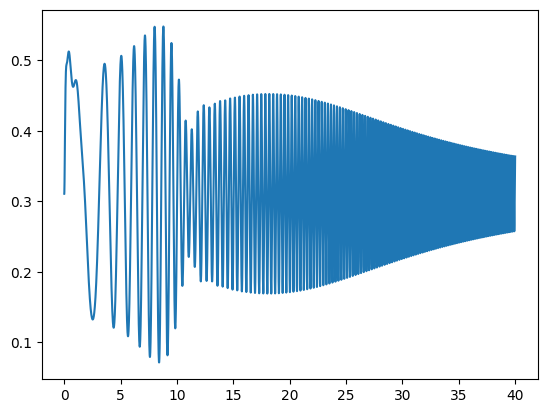

In [40]:
plt.figure()
plt.plot(t, yprova)

In [41]:
'''search_space = [
    Real(100, 5000, name='Kb'),
    Real(100, 5000, name='Kr'),
    Real(10, 100, name='Mb'),
    Real(0.1, 0.3, name='hb'),
    Real(0.1, 1.1, name='hr'),
    Real(1e-4, 1e-2, name='f0'),
    Real(3, 10, name='f1'),
    Real(0.1, 0.2, name='A_sin'),
    Real(0.3, 0.5, name='x_r_start')
]'''

"search_space = [\n    Real(100, 5000, name='Kb'),\n    Real(100, 5000, name='Kr'),\n    Real(10, 100, name='Mb'),\n    Real(0.1, 0.3, name='hb'),\n    Real(0.1, 1.1, name='hr'),\n    Real(1e-4, 1e-2, name='f0'),\n    Real(3, 10, name='f1'),\n    Real(0.1, 0.2, name='A_sin'),\n    Real(0.3, 0.5, name='x_r_start')\n]"

In [42]:
# Definiamo i valori di partenza (presi dal tuo modello precedente)
start_constant = best_gpr.kernel_.k1.k1.constant_value
start_ls = best_gpr.kernel_.k1.k2.length_scale
start_nu = best_gpr.kernel_.k1.k2.nu
start_noise = best_gpr.kernel_.k2.noise_level
print(f'The INITIAL variance of the NOISE is: {start_noise}')
print(f'The INITIAL variance of the CONSTANT is: {start_constant}')
print(f'The INITIAL LENGTH SCALE of the is: {start_ls}')
print(f'The NU SCALE of the is: {start_nu}')

The INITIAL variance of the NOISE is: 9.999999999999997e-06
The INITIAL variance of the CONSTANT is: 1445.8183575614169
The INITIAL LENGTH SCALE of the is: [ 103.62247193   97.16183299   41.30728275 1537.37818383   17.92317388
 2698.58905527 3911.47033386  119.38990277  282.43090669]
The NU SCALE of the is: 1.5


In [107]:
from skopt import gp_minimize
from skopt.learning import GaussianProcessRegressor
from skopt.learning.gaussian_process.kernels import Matern
from skopt.learning.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel

from skopt.learning import GaussianProcessRegressor
from skopt.learning.gaussian_process.kernels import (
    ConstantKernel as C,
    Matern,
    WhiteKernel as W,
)




# 2. Ricostruiamo il kernel "fresco"
# Nota: ho rimosso "fixed" dai bounds per permettere al nuovo GPR di ottimizzarli 
# se optimizer è attivo, o semplicemente per non avere un oggetto bloccato.

'''
fresh_skopt_kernel = (
    C(start_constant, (1e-3, 1e5)) * 
    Matern(length_scale=start_ls, nu=start_nu, length_scale_bounds=(1e-3, 1e3)) + 
    W(noise_level=start_noise, noise_level_bounds=(1e-8, 1e-4))) # 1e-5,1e1
'''

fresh_skopt_kernel = (
    C(start_constant, (1e-3, 1e5)) * 
    Matern(length_scale=start_ls, nu=2.5, length_scale_bounds=(1e-3, 1e5)) + 
    W(noise_level=start_noise, noise_level_bounds=(1e-8, 1e-4))) # 1e-5,1e1, i changed nu  and lengthscalebound from 1e3


gpr = GaussianProcessRegressor(
    kernel=fresh_skopt_kernel,
    optimizer="fmin_l_bfgs_b",  # Lo ottimizza ad ogni passo
    n_restarts_optimizer=10,     # Più stabilità nell'ottimizzazione
    random_state=42,
    normalize_y=True 
)

# 2. Wrap it in a Regressor and set optimizer=None
# This is the "secret sauce" that stops retraining

my_seed = 42


# 3. Pass this estimator into gp_minimize

res = gp_minimize(
    loss_function,
    search_space_s,
    base_estimator = gpr,
    n_calls = 150, # 40      # Total calls  10
    n_initial_points = 40,    # 30  # initial dataset before doing the acquisition, rn we are just selecting random points 5
    acq_func = "EI",
    xi = 0.05,  # <-- AGGIUNTO: forza maggiore esplorazione
    acq_optimizer = "lbfgs", # instead of acq_optimizer = "sampling"
    random_state = my_seed
)

In [108]:
best_model_final = res.models[-1]

# Ora puoi accedere al kernel ottimizzato

print("Kernel finale ottimizzato:")
print(best_model_final.kernel_)

Kernel finale ottimizzato:
1.59**2 * Matern(length_scale=[4.29, 1.4, 0.621, 3.04, 0.539, 3.4, 3.44, 2.98, 3.91], nu=2.5) + WhiteKernel(noise_level=0.0001)


In [109]:
res

          fun: -1.4629754499518164
            x: [0.8887369728684401, 0.87755295340765, 0.0, 0.0, 0.0, 1.0, 0.43508705765147826, 1.0, 1.0]
    func_vals: [-7.235e-01 -6.109e-01 ... -1.151e+00 -8.692e-01]
      x_iters: [[0.37454011884736255, 0.9507143064099164, 0.7319939418114052, 0.5986584841970367, 0.15601864044243655, 0.15599452033620267, 0.058083612168199475, 0.8661761457749354, 0.6011150117432089], [0.7080725777960456, 0.02058449429580245, 0.9699098521619945, 0.832442640800422, 0.2123391106782762, 0.18182496720710065, 0.18340450985343384, 0.3042422429595378, 0.524756431632238], [0.4319450186421159, 0.29122914019804197, 0.6118528947223796, 0.13949386065204186, 0.2921446485352182, 0.36636184329369176, 0.45606998421703604, 0.7851759613930138, 0.1996737821583598], [0.5142344384136117, 0.5924145688620426, 0.04645041271999773, 0.6075448519014385, 0.17052412368729156, 0.06505159298527953, 0.9488855372533335, 0.9656320330745596, 0.8083973481164614], [0.30461376917337074, 0.09767211400638

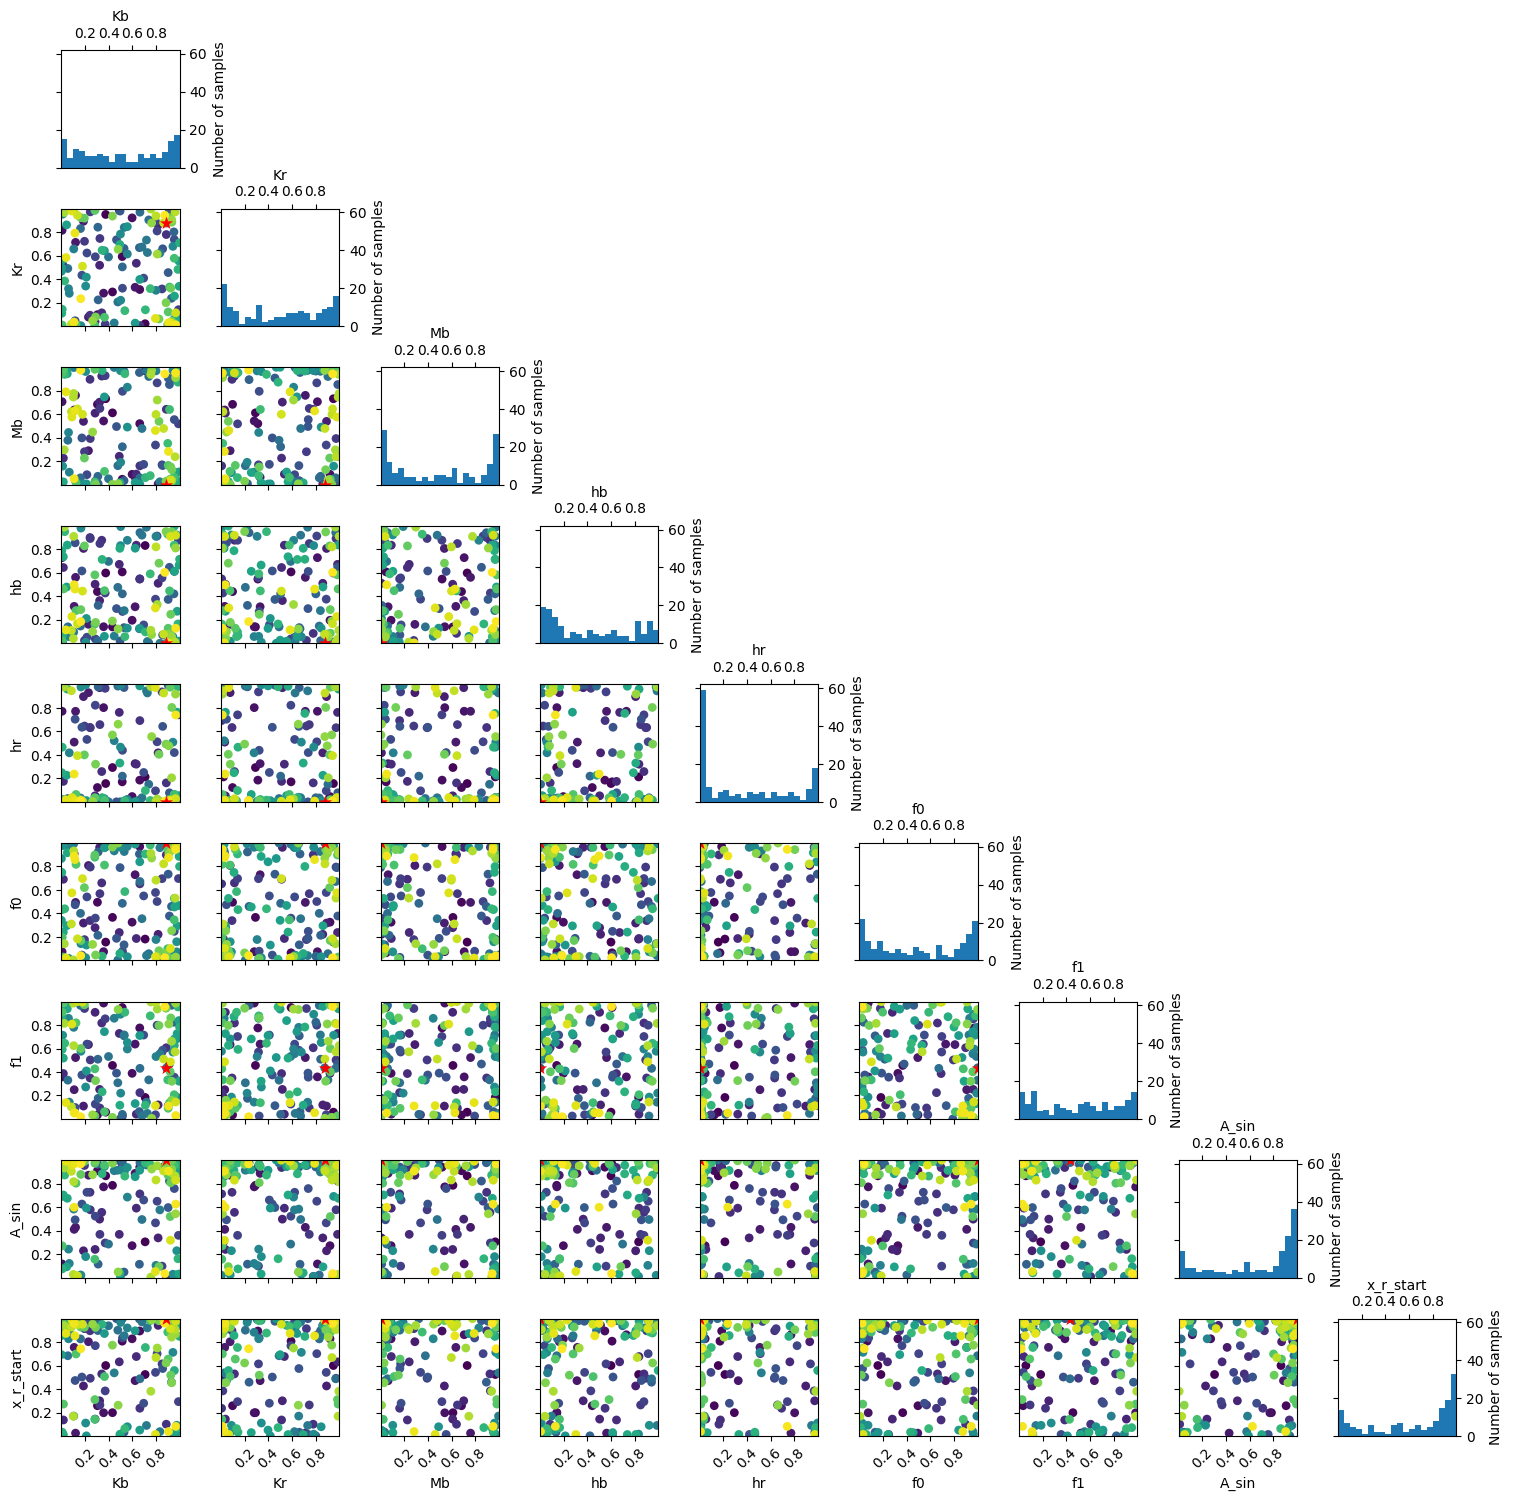

In [110]:
import matplotlib.pyplot as plt
from skopt.plots import plot_evaluations

# Genera la Scatter Matrix completa per tutti i parametri dell'oggetto res
_ = plot_evaluations(res)
plt.show()

In [111]:
# Save the dataset found by BO
n_punti_iniziali = 40

X_init_scaled = np.array(res.x_iters)   # Primi 40 vettori (scalati 0-1)
Y_init_loss = np.array(res.func_vals)   # Primi 40 valori restituiti dalla loss (-max_disp)

# 2. Riporta i parametri X alle unità di misura fisiche reali
X_init_phys = scaler_x_min.inverse_transform(X_init_scaled)

# 3. Trasforma la Y nel massimo spostamento reale (invertendo il segno meno della loss)
Y_init_max_disp = np.abs(Y_init_loss)

# 4. Organizza tutto in un comodo DataFrame di Pandas
df_primo_dataset = pd.DataFrame(X_init_phys, columns=param_names)
df_primo_dataset['true_max_disp'] = Y_init_max_disp

print("--- ANTEPRIMA DEL PRIMO DATASET DELLA BO ---")
print(df_primo_dataset.head())
print(f"\nDimensione totale del dataset iniziale: {df_primo_dataset.shape}") # Dovrebbe essere (40, 10)

# =====================================================================
# 5. OPZIONI DI SALVATAGGIO (Scegli quella che preferisci)
# =====================================================================

# Opzione A: Salva in formato CSV (Separato da virgole)
df_primo_dataset.to_csv('primo_dataset_BO.csv', index=False)

# Opzione B: Salva in formato Excel (Richiede che tu abbia installato openpyxl)
# df_primo_dataset.to_excel('primo_dataset_BO.xlsx', index=False)

# Opzione C: Salva direttamente le matrici NumPy native se ti servono per altri script
# np.save('X_init_phys.npy', X_init_phys)
# np.save('Y_init_max_disp.npy', Y_init_max_disp)

print("\nDataset salvato con successo!")

--- ANTEPRIMA DEL PRIMO DATASET DELLA BO ---
            Kb           Kr         Mb        hb        hr        f0  \
0  1944.662963  4754.604393  75.878256  0.219687  0.257000  0.001665   
1  3570.920695   216.916840  97.248569  0.266217  0.313051  0.001919   
2  2224.561244  1537.271080  65.086830  0.128301  0.392475  0.003732   
3  2625.792973  3006.620146  14.300702  0.221456  0.271436  0.000771   
4  1603.711839   592.992876  71.588228  0.188140  0.223182  0.004998   

         f1     A_sin  x_r_start  true_max_disp  
0  3.414824  0.186315   0.420146       0.723514  
1  4.289127  0.130476   0.404909       0.610863  
2  6.191382  0.178266   0.340040       0.563469  
3  9.629516  0.196198   0.461508       0.847731  
4  3.249515  0.190603   0.351835       0.650877  

Dimensione totale del dataset iniziale: (150, 10)

Dataset salvato con successo!


### [3.2] Optimal Parameters

In [112]:
# The best set of parameters found
x_best = res.x

# The best objective value (the minimum found)

# Note: If your objective returned -max_disp, this will be a negative number
y_best = res.fun

print(x_best)
print(y_best)

[0.8887369728684401, 0.87755295340765, 0.0, 0.0, 0.0, 1.0, 0.43508705765147826, 1.0, 1.0]
-1.4629754499518164


In [113]:
# x_best_s è il vettore "piccolo" (scalato)
x_best_s = np.array(res.x).reshape(1, -1)

# Applichiamo l'inversa per tornare alle unità di misura reali
x_best = scaler_x_min.inverse_transform(x_best_s).flatten()
y_best = np.abs(res.fun)

# Ora puoi stamparli con i loro nomi
print("--- REAL OPTIMAL PARAMETERS ---")
for name, value in zip(param_names, x_best):
    print(f"{name}: {value:.4f}")

print("--- MAX DISP ---")
print(f"The max disp is: {y_best}")

--- REAL OPTIMAL PARAMETERS ---
Kb: 4451.8151
Kr: 4397.6829
Mb: 10.1284
hb: 0.1005
hr: 0.1017
f0: 0.0100
f1: 6.0450
A_sin: 0.1996
x_r_start: 0.4997
--- MAX DISP ---
The max disp is: 1.4629754499518164


In [52]:
# visualization of the convergence history

print("List of parameter vectors (v1, v2, ...):")
for i, l in enumerate(res.x_iters, start = 1):
    print(f"l{i}: {l}")


print('All fun history:', res.func_vals)


List of parameter vectors (v1, v2, ...):
l1: [0.37454011884736255, 0.9507143064099164, 0.7319939418114052, 0.5986584841970367, 0.15601864044243655, 0.15599452033620267, 0.058083612168199475, 0.8661761457749354, 0.6011150117432089]
l2: [0.7080725777960456, 0.02058449429580245, 0.9699098521619945, 0.832442640800422, 0.2123391106782762, 0.18182496720710065, 0.18340450985343384, 0.3042422429595378, 0.524756431632238]
l3: [0.4319450186421159, 0.29122914019804197, 0.6118528947223796, 0.13949386065204186, 0.2921446485352182, 0.36636184329369176, 0.45606998421703604, 0.7851759613930138, 0.1996737821583598]
l4: [0.5142344384136117, 0.5924145688620426, 0.04645041271999773, 0.6075448519014385, 0.17052412368729156, 0.06505159298527953, 0.9488855372533335, 0.9656320330745596, 0.8083973481164614]
l5: [0.30461376917337074, 0.0976721140063839, 0.684233026512157, 0.4401524937396014, 0.12203823484477885, 0.4951769101112703, 0.0343885211152184, 0.9093204020787823, 0.258779981600017]
l6: [0.66252228435398

In [53]:
max_disp_best, disp_best, xb_opt, xr_opt = simulate_peak_joint_position(x_best)
max_disp_best
disp_best.shape

(800000,)

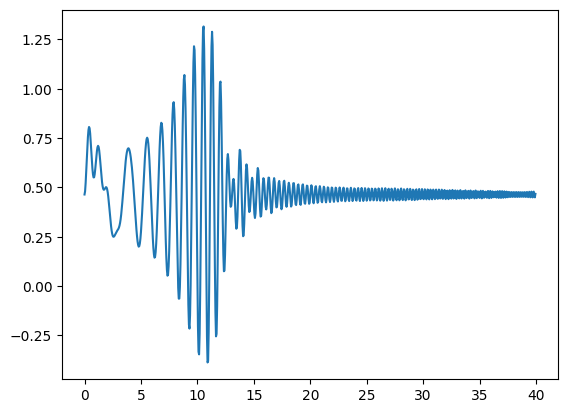

In [54]:
%matplotlib inline
t = np.linspace(0,Tsim,int(Tsim/Ts))


plt.figure()
plt.plot(t[::1000], disp_best[::1000])
plt.show()

In [ ]:
# DO BO for DIFFERENT SEEDS (MORE then 20 min)

# Dizionario per salvare gli oggetti in RAM
results_dict = {}
seeds = [42, 101, 2024, 777, 99] #SEEDS TO TEST


for seed in seeds:
    print(f"--- Start Bayesian Optimization | Seed {seed} ---")

    res = gp_minimize(
        loss_function,
        search_space_s,
        base_estimator=gpr,
        n_calls=150,
        n_initial_points=40,
        acq_func="EI",
        xi = 0.05,  # <-- AGGIUNTO: forza maggiore esplorazione
        acq_optimizer="sampling", # instead of acq_optimizer = "sampling"
        random_state=seed,
    )

    # A. Salvataggio in memoria (RAM)
    results_dict[seed] = res

    print(
        f"Completato Seed {seed}! Miglior valore trovato: {np.min(res.func_vals):.4f}") # Min because we have a - sign in loss function

--- Start Bayesian Optimization | Seed 42 ---
Completato Seed 42! Miglior valore trovato: -1.3239
--- Start Bayesian Optimization | Seed 101 ---
Completato Seed 101! Miglior valore trovato: -1.3068
--- Start Bayesian Optimization | Seed 2024 ---
Completato Seed 2024! Miglior valore trovato: -1.3291
--- Start Bayesian Optimization | Seed 777 ---
Completato Seed 777! Miglior valore trovato: -1.2507
--- Start Bayesian Optimization | Seed 99 ---
Completato Seed 99! Miglior valore trovato: -1.2453


# [4] Dynamic System Animation

### 1DOF system

In [58]:

def one_dof_system(t, state, p):
    """
    Single-mass spring-damper system ODE.
    State vector: [x, v] (position and velocity)
    p is the dictionary with best parameters
    """
    x, v = state

    # Extract params
    K = p['K']       # Spring stiffness
    M = p['M']       # Mass
    h = p['h']       # Damping ratio
    A_sin = p['A_sin']
    f0, f1 = p['f0'], p['f1']
    Tsim = p['Tsim']

    # Compute Chirp Signal for the Base (Excitation)
    # This represents the floor or wall moving
    x_base = chirp_signal(t, f0, f1, Tsim, A_sin)

    # Calculate Damping Coefficient (c = 2 * h * sqrt(K*M))
    c = 2 * h * np.sqrt(K * M)

    # Equation of Motion: M*a + c*(v - v_base) + K*(x - x_base) = 0
    # Rearranged for acceleration:
    # We assume base velocity v_base is small or focus on the displacement excitation:

    # a = (-c*v - K*(x - x_base)) / M
    accel = (-c * v - K * (x - x_base)) / M

    return [v, accel]

In [59]:
indices = [1, 4, 5, 6, 7] # Kr, hr,f0,f1,A_sin
extracted_values = [x_best[i] for i in indices]
extracted_values

[np.float64(706.0448730679248),
 np.float64(0.10260948022983944),
 np.float64(0.0049791674903452154),
 np.float64(5.221147839143479),
 np.float64(0.19852191176898654)]

In [60]:
p = {
"K": extracted_values[0],
"M": Mr,
"h": extracted_values[1],
"A_sin": extracted_values[-1],
"f0": extracted_values[2],
"f1": extracted_values[3],
"Tsim": Tsim
}

In [61]:
# Starting at rest

y0 = [x_best[-1], 0.0]
sol = solve_ivp(one_dof_system, [0, Tsim], y0, args=(p, ), method='RK45')

In [62]:
disp_onedof = sol.y[0]
disp_onedof.shape
max_disp_onedof = max(disp_onedof)

0.8062739667225174


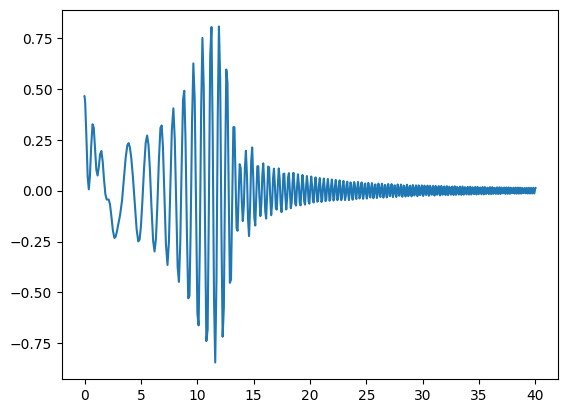

In [63]:
print(max(disp_onedof))

plt.figure()
plt.plot(sol.t,disp_onedof)


### 2DOF Mass-Spring-Damper System Animation

In [64]:
from matplotlib.animation import FuncAnimation
'''

start_time = 0.0
end_time = 40.0

visual_step = int(0.004 / Ts)
# 2. Subsample the result arrays
t_plot = t[::visual_step]
xb_plot = xb_opt[::visual_step]
xr_plot = xr_opt[::visual_step]
disp_onedof_plot = disp_onedof[::visual_step]


# Find indices in t_plot
idx_start = np.abs(t_plot - start_time).argmin()
idx_end = np.abs(t_plot - end_time).argmin()

# Slice the data to the specific interval
t_window = t_plot[idx_start:idx_end]
xb_window = xb_plot[idx_start:idx_end]
xr_window = xr_plot[idx_start:idx_end]
disp_onedof_window = disp_onedof_plot[idx_start:idx_end]

# --- 2. Setup Figure ---
fig, ax = plt.subplots()
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-1, 1)
ax.set_aspect('equal')
ax.set_title(f'2DOF System: {start_time}s to {end_time}s')

wall_x = 0.0
L1 = 0
L2 = x_best[-1]
h = 0.3 # vertical line length

# -- create the graphical object as 'empty shells' ---
masses, = ax.plot([], [], 'o', ms=20, color='royalblue')
spring_line1, = ax.plot([], [], '-', color='gray', lw=1)
spring_line2, = ax.plot([], [], '-', color='red', lw=1)
time_template = 'Time = %.2fs'
time_text = ax.text(0.05, 0.9, '', transform=ax.transAxes)
# Fixed wall at x = xr_start and the time history is disp_onedof
# ax.axvline(x=x_best[-1]+max_disp_onedof, color='black', lw=3)
# ax.axvline(max_disp_onedof,  color='black', lw=3)
ax.plot([max_disp_onedof, max_disp_onedof], [-h, h], color='black', lw=3, label='Limit')
# Define the Y limits for the vertical line to span the plot height
y_limits = [-1, 1] 
moving_line, = ax.plot([], [], color='black', lw=2, linestyle='--', label='1DOF Ref')

# --- 3. Animation Functions ---

def init():
    masses.set_data([], [])
    spring_line1.set_data([], [])
    spring_line2.set_data([], [])
    time_text.set_text('')
    moving_line.set_data([],[]) # Placeholder for init
    return masses, spring_line1, spring_line2, time_text, moving_line

def update(frame):
    # CRITICAL: Use the windowed data here
    current_time = t_window[frame]
    curr_x1 = xb_window[frame] + L1 # displacement of the base
    relative_start_pos = x_best[-1] # relative start position
    curr_x2 = curr_x1 + xr_window[frame] # displacment of the base + relative displacement of the robot
    curr_x3 = xr_window[frame]  # relative displacement of the robot
    
    
    # Update the vertical line position
    moving_line.set_data([curr_x3, curr_x3],[-h,h])

    masses.set_data([curr_x1, curr_x2], [0, 0])
    spring_line1.set_data([curr_x1, curr_x2], [0, 0])
    spring_line2.set_data([wall_x, curr_x1], [0, 0])
    time_text.set_text(time_template % current_time)

    
    return masses, spring_line1, spring_line2, time_text, moving_line

# --- 4. Run Animation ---
# We use step=1 for a smooth windowed view, or keep 50 if it's too slow
step = 10 # 每隔 5 个点画一帧，跨度为 0.02s
# 物理跨度 = visual_step * step * Ts = 0.004 * 5 = 0.02s

# 为了匹配真实时间，interval 应该设为 20ms (即每秒 50 帧)
# 计算公式：interval = (visual_step * step) * 1000
# 如果你想要 1:1 真实时间感：
actual_interval = 40 #20

ani = FuncAnimation(
    fig,
    update,
    frames=range(0, len(t_window), step),
    init_func=init,
    interval=actual_interval,
    blit=True
)

from IPython.display import HTML
HTML(ani.to_jshtml())
'''

"\n\nstart_time = 0.0\nend_time = 40.0\n\nvisual_step = int(0.004 / Ts)\n# 2. Subsample the result arrays\nt_plot = t[::visual_step]\nxb_plot = xb_opt[::visual_step]\nxr_plot = xr_opt[::visual_step]\ndisp_onedof_plot = disp_onedof[::visual_step]\n\n\n# Find indices in t_plot\nidx_start = np.abs(t_plot - start_time).argmin()\nidx_end = np.abs(t_plot - end_time).argmin()\n\n# Slice the data to the specific interval\nt_window = t_plot[idx_start:idx_end]\nxb_window = xb_plot[idx_start:idx_end]\nxr_window = xr_plot[idx_start:idx_end]\ndisp_onedof_window = disp_onedof_plot[idx_start:idx_end]\n\n# --- 2. Setup Figure ---\nfig, ax = plt.subplots()\nax.set_xlim(-0.5, 2.5)\nax.set_ylim(-1, 1)\nax.set_aspect('equal')\nax.set_title(f'2DOF System: {start_time}s to {end_time}s')\n\nwall_x = 0.0\nL1 = 0\nL2 = x_best[-1]\nh = 0.3 # vertical line length\n\n# -- create the graphical object as 'empty shells' ---\nmasses, = ax.plot([], [], 'o', ms=20, color='royalblue')\nspring_line1, = ax.plot([], [], '-

### Assesment of the model results

In [114]:
x_best # are the optimal parameters in the REAL scale
y_best # is the optimal displacement


# simulate for 1 set of parameters

x_best_reshaped = np.array(x_best_s).reshape(1, -1)


true_max_disp, y_signal_test, _, _ = simulate_peak_joint_position(x_best)
surrogate_pred, surrogate_std = best_model_final.predict(x_best_reshaped, return_std=True)

surrogate_pred = np.abs(surrogate_pred)
print(surrogate_pred.shape)
print(surrogate_pred)



(1,)
[1.46256272]


In [115]:
# error computation

abs_error = np.abs(true_max_disp - surrogate_pred[0])
rel_error = (abs_error / true_max_disp) * 100

# smse = np.mean(true_max_disp - surrogate_pred[0])**2/(surrogate_std**2)
smse = ((true_max_disp - surrogate_pred[0])**2) / (surrogate_std[0]**2)
print(smse.shape)

()


In [116]:
# --- Display Results ---
print("--- SURROGATE PERFORMANCE ASSESSMENT ---")
print(f"Optimal Parameters (x_best): {x_best}")
print(f"Physics Simulator Result (True): {true_max_disp:.6f} m")
print(f"GP Surrogate Prediction:         {surrogate_pred[0]:.6f} m")
print(f"GP Confidence (Std Dev):         {surrogate_std[0]:.6f}")
# print(f'The maximum displacement predicted is: {res.fun} m')
print("-" * 40)
print(f"Absolute Error:                  {abs_error:.6f} m")
print(f"Relative Error:                  {rel_error:.4f} %")
print(f"SMSE Error:                  {smse:.4f} %")

if rel_error < 1.0:
    print("Assessment: Excellent! The surrogate is highly accurate at the optimum.")
elif rel_error < 5.0:
    print("Assessment: Good. The surrogate captures the physics well.")
else:
    print("Assessment: Warning. Significant discrepancy between surrogate and physics.")

--- SURROGATE PERFORMANCE ASSESSMENT ---
Optimal Parameters (x_best): [4.45181508e+03 4.39768286e+03 1.01283879e+01 1.00537470e-01
 1.01726594e-01 9.95837669e-03 6.04499407e+00 1.99613400e-01
 4.99741772e-01]
Physics Simulator Result (True): 1.462975 m
GP Surrogate Prediction:         1.462563 m
GP Confidence (Std Dev):         0.003232
----------------------------------------
Absolute Error:                  0.000413 m
Relative Error:                  0.0282 %
SMSE Error:                  0.0163 %
Assessment: Excellent! The surrogate is highly accurate at the optimum.


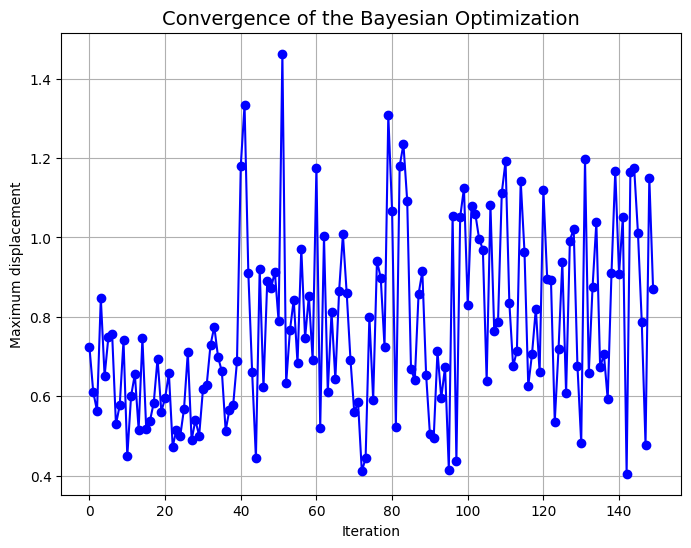

In [117]:
# PLOT CONVERGENCE RATE

plt.figure(figsize = (8,6))
plt.plot(np.abs(res.func_vals),marker = 'o', color = 'blue', label = 'Convergence plot')
plt.title('Convergence of the Bayesian Optimization', fontsize = 14)
plt.xlabel('Iteration')
plt.ylabel('Maximum displacement')
plt.grid(True)

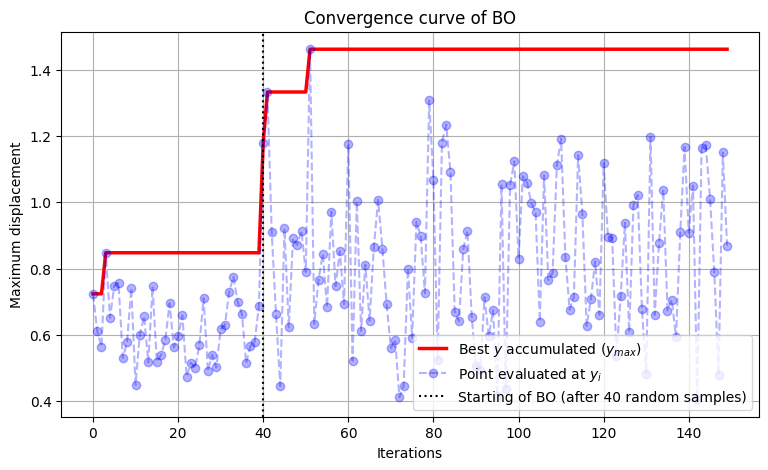

In [118]:
import matplotlib.pyplot as plt
import numpy as np

# Se la loss restituisce lo spostamento direttamente:
y_eval = np.abs(res.func_vals)

# Calcoliamo il massimo accumulato passo dopo passo
y_max_accumulato = np.maximum.accumulate(y_eval)

iterazioni = np.arange(len(y_eval))

plt.figure(figsize=(9, 5))

# 1. Curva reale di convergenza (Miglior valore trovato finora)
plt.plot(
    iterazioni,
    y_max_accumulato,
    color="red",
    linewidth=2.5,
    label="Best $y$ accumulated ($y_{max}$)",
)

# 2. Singole valutazioni dell'algoritmo (i punti blu del tuo grafico)
plt.plot(
    iterazioni,
    y_eval,
    color="blue",
    alpha=0.3,
    linestyle="--",
    marker="o",
    label="Point evaluated at $y_i$",
)

plt.axvline(
    x=40,
    color="black",
    linestyle=":",
    label="Starting of BO (after 40 random samples)",
)

plt.xlabel("Iterations")
plt.ylabel("Maximum displacement")
plt.title("Convergence curve of BO")
plt.legend()
plt.grid(True)
plt.show()

In [119]:
len(results_dict)
results_dict.keys()
results_dict[42]

          fun: -1.3238783558513196
            x: [0.9311964877735821, 0.12084537828816613, 0.02800867183472567, 0.5037162456810012, 0.0008871259900505859, 0.4932715876374508, 0.3169985381847607, 0.9890158871858384, 0.8208795729400106]
    func_vals: [-7.235e-01 -6.109e-01 ... -1.178e+00 -6.010e-01]
      x_iters: [[0.37454011884736255, 0.9507143064099164, 0.7319939418114052, 0.5986584841970367, 0.15601864044243655, 0.15599452033620267, 0.058083612168199475, 0.8661761457749354, 0.6011150117432089], [0.7080725777960456, 0.02058449429580245, 0.9699098521619945, 0.832442640800422, 0.2123391106782762, 0.18182496720710065, 0.18340450985343384, 0.3042422429595378, 0.524756431632238], [0.4319450186421159, 0.29122914019804197, 0.6118528947223796, 0.13949386065204186, 0.2921446485352182, 0.36636184329369176, 0.45606998421703604, 0.7851759613930138, 0.1996737821583598], [0.5142344384136117, 0.5924145688620426, 0.04645041271999773, 0.6075448519014385, 0.17052412368729156, 0.06505159298527953, 0.9

(150,)
(1, 150)
(150,)
(2, 150)
(150,)
(3, 150)
(150,)
(4, 150)
(150,)
(5, 150)


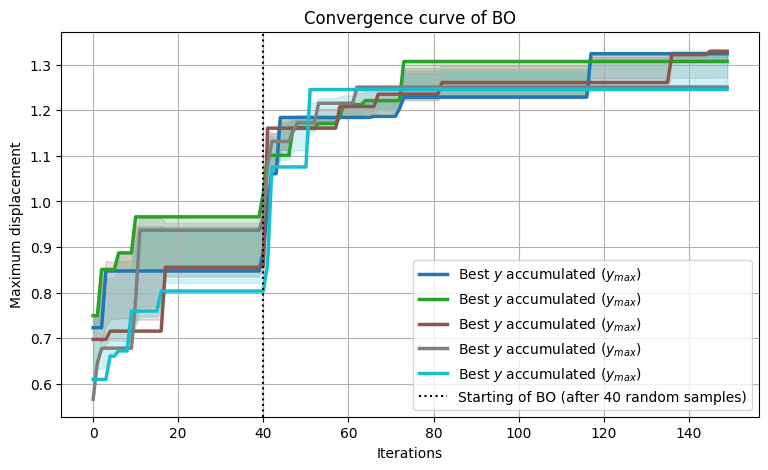

In [72]:
# PLOT for DIFFERENT SEEDS

num_seeds = len(results_dict)
colors = plt.cm.tab10(np.linspace(0, 1, num_seeds)) # PALETTE OF COLORS
y_max_store = []

plt.figure(figsize=(9, 5))

for i in range(len(results_dict)):
    res_seed = results_dict[seeds[i]]
    # Se la loss restituisce lo spostamento direttamente:
    y_eval = np.abs(res_seed.func_vals)

    # Calcoliamo il massimo accumulato passo dopo passo
    y_max_accumulato = np.maximum.accumulate(y_eval)
    # store for mean and std
    print(y_max_accumulato.shape)
    y_max_store.append(y_max_accumulato)
    print(np.array(y_max_store).shape)
    mn_y_cumulated = np.mean(y_max_store, axis=0)
    std_y_cumulated = np.std(y_max_store, axis=0)

    iterazioni = np.arange(len(y_eval))

    # Convergence curve for each seed
    plt.plot(
        iterazioni,
        y_max_accumulato,
        color= colors[i],
        linewidth=2.5,
        label="Best $y$ accumulated ($y_{max}$)",
    )

    plt.fill_between(
        iterazioni,
        mn_y_cumulated - std_y_cumulated,
        mn_y_cumulated + std_y_cumulated,
        color=colors[i],
        alpha=0.2
    )
    '''
    # 2. Singole valutazioni dell'algoritmo (i punti blu del tuo grafico)
    plt.plot(
        iterazioni,
        y_eval,
        color="blue",
        alpha=0.3,
        linestyle="--",
        marker="o",
        label="Point evaluated at $y_i$",
    )'''

plt.axvline(
    x=40,
    color="black",
    linestyle=":",
    label="Starting of BO (after 40 random samples)",
)

plt.xlabel("Iterations")
plt.ylabel("Maximum displacement")
plt.title("Convergence curve of BO")
plt.legend()
plt.grid(True)
plt.show()

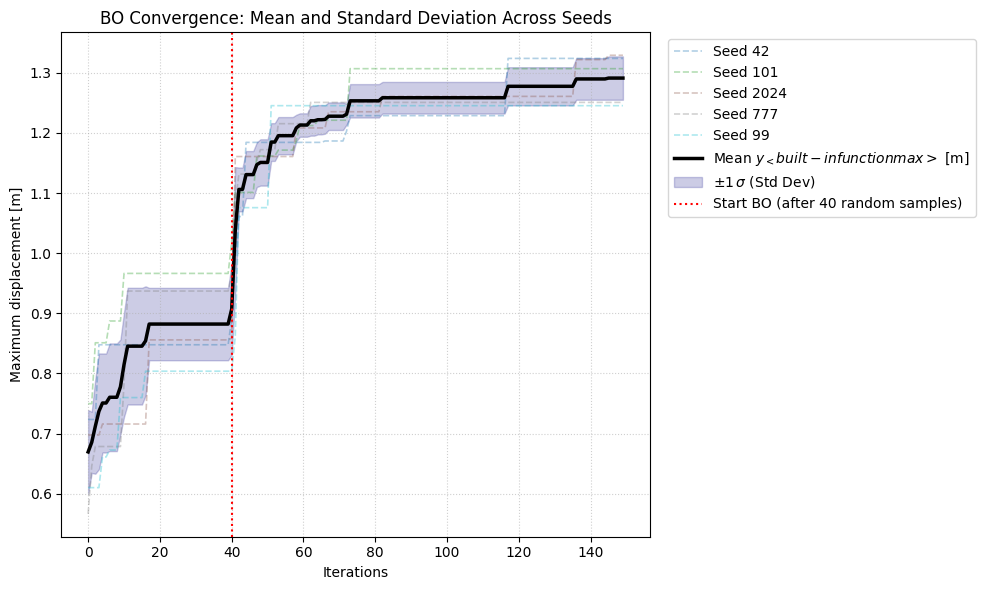

In [73]:
import matplotlib.pyplot as plt
import numpy as np

num_seeds = len(results_dict)
colors = plt.cm.tab10(np.linspace(0, 1, num_seeds))
y_max_store = []

# ==========================================
# 1. RACCOLTA DATI DA TUTTI I SEED
# ==========================================
for i, seed in enumerate(seeds):
    res_seed = results_dict[seed]

    # Estraggo e calcolo il massimo accumulato
    y_eval = np.abs(res_seed.func_vals)
    y_max_accumulato = np.maximum.accumulate(y_eval)

    # Salvo la curva nella lista
    y_max_store.append(y_max_accumulato)

# Convertiamo in un array NumPy 2D di forma: (num_seeds, num_iterazioni)
y_max_matrix = np.array(y_max_store)
iterazioni = np.arange(y_max_matrix.shape[1])

# ==========================================
# 2. CALCOLO STATISTICO (Media e Dev. Std)
# ==========================================
# axis=0 calcola la media e la std colonna per colonna (lungo i seed)
mean_y = np.mean(y_max_matrix, axis=0)
std_y = np.std(y_max_matrix, axis=0)

# ==========================================
# 3. GRAFICO CON FASCIA COLORATA
# ==========================================
plt.figure(figsize=(10, 6))

# A. (Opzionale) Tracciamo le singole curve dei seed trasparenti in sottofondo
for i in range(num_seeds):
    plt.plot(
        iterazioni,
        y_max_matrix[i],
        color=colors[i],
        alpha=0.35,
        linewidth=1.2,
        linestyle="--",
        label=f"Seed {seeds[i]}",
    )

# B. Linea della MEDIA (spessa e ben visibile)
plt.plot(
    iterazioni,
    mean_y,
    color="black",
    linewidth=2.5,
    label= f"Mean $y_{max}$ [m] ",
)

# C. FASCIA COLORATA DELLA DEVIAZIONE STANDARD (Media ± 1 Std)
plt.fill_between(
    iterazioni,
    mean_y - std_y,  # Limite inferiore della fascia
    mean_y + std_y,  # Limite superiore della fascia
    color="navy",  # Colore della fascia
    alpha=0.2,  # Trasparenza (0 = invisibile, 1 = opaco)
    label="$\pm 1\,\sigma$ (Std Dev)",
)

# D. Formattazione e Legenda
plt.axvline(
    x=40,
    color="red",
    linestyle=":",
    linewidth=1.5,
    label="Start BO (after 40 random samples)",
)

plt.xlabel("Iterations")
plt.ylabel("Maximum displacement [m]")
plt.title("BO Convergence: Mean and Standard Deviation Across Seeds")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()

plt.show()

In [74]:
X_try_s = scaler_x_min.transform(X_test)
print(X_try_s.shape)
# simulate for 1 set of parameters

X_try_s_reshaped = np.array(X_try_s[3,:]).reshape(1, -1)
print(X_try_s_reshaped)

(44, 9)
[[0.65305036 0.59688766 0.04953481 0.26181666 0.43948645 0.71687955
  0.28425665 0.95270958 0.57215749]]


In [75]:

# simulate for 1 set of parameters

true_max_disp_try, y_signal_test_try, _, _ = simulate_peak_joint_position(X_test[3,:])
surrogate_pred_try, surrogate_std_try = best_model_final.predict(X_try_s_reshaped, return_std=True)

surrogate_pred_try = np.abs(surrogate_pred_try)
print(surrogate_pred_try.shape)
print(surrogate_pred_try)
print(true_max_disp_try)

(1,)
[0.75927414]
0.7754250463565115


In [76]:
# error computation

abs_error_try = np.abs(true_max_disp_try - surrogate_pred_try[0])
rel_error_try = (abs_error_try / true_max_disp_try) * 100

# smse = np.mean(true_max_disp - surrogate_pred[0])**2/(surrogate_std**2)
smse_try = ((true_max_disp_try - surrogate_pred_try[0])**2) / (surrogate_std_try[0]**2)
print(smse_try.shape)

()


In [77]:
# --- Display Results ---
print("--- SURROGATE PERFORMANCE ASSESSMENT ---")
print(f"Optimal Parameters (x_best): {X_test[3,:]}")
print(f"Physics Simulator Result (True): {true_max_disp_try:.6f} m")
print(f"GP Surrogate Prediction:         {surrogate_pred_try[0]:.6f} m")
print(f"GP Confidence (Std Dev):         {surrogate_std_try[0]:.6f}")
# print(f'The maximum displacement predicted is: {res.fun} m')
print("-" * 40)
print(f"Absolute Error:                  {abs_error_try:.6f} m")
print(f"Relative Error:                  {rel_error_try:.4f} %")
print(f"SMSE Error:                  {smse_try:.4f} %")

if rel_error_try < 1.0:
    print("Assessment: Excellent! The surrogate is highly accurate at the optimum.")
elif rel_error_try < 5.0:
    print("Assessment: Good. The surrogate captures the physics well.")
else:
    print("Assessment: Warning. Significant discrepancy between surrogate and physics.")

--- SURROGATE PERFORMANCE ASSESSMENT ---
Optimal Parameters (x_best): [3.30264004e+03 3.02844236e+03 1.45777515e+01 1.52646325e-01
 5.39112570e-01 7.17638159e-03 4.99272363e+00 1.94914165e-01
 4.14367731e-01]
Physics Simulator Result (True): 0.775425 m
GP Surrogate Prediction:         0.759274 m
GP Confidence (Std Dev):         0.077824
----------------------------------------
Absolute Error:                  0.016151 m
Relative Error:                  2.0828 %
SMSE Error:                  0.0431 %
Assessment: Good. The surrogate captures the physics well.


In [78]:
# Doing the assessment on the whole test set:

X_try_s = scaler_x_min.transform(X_test)
print(X_try_s.shape)
X_try_s_reshaped = np.array(X_try_s[3,:]).reshape(1, -1)
print(X_try_s_reshaped)

(44, 9)
[[0.65305036 0.59688766 0.04953481 0.26181666 0.43948645 0.71687955
  0.28425665 0.95270958 0.57215749]]


In [79]:
# initialization of the containers

TRUE_MAX_val = []
MEAN_val = []
STD_val = []



# simulate for 1 set of parameters


for i in range(X_test.shape[0]):
    # get the TRUE values
    true_max_disp_try, y_signal_test_try, _, _ = simulate_peak_joint_position(X_test[i,:])
    # get the reshaped scaled version of each test vector
    X_try_s_reshaped = np.array(X_try_s[i,:]).reshape(1, -1)
    # get the PREDICTION values
    surrogate_pred_try, surrogate_std_try = best_model_final.predict(X_try_s_reshaped, return_std=True)
    surrogate_pred_try = np.abs(surrogate_pred_try)

    # append the values in their container

    TRUE_MAX_val.append(true_max_disp_try)
    MEAN_val.append(surrogate_pred_try)
    STD_val.append(surrogate_std_try)

    

In [80]:
# checking the shape
print(X_test.shape)
# conversion to np.array()
TRUE_MAX_val = np.array(TRUE_MAX_val)
MEAN_val = np.array(MEAN_val)
STD_val = np.array(STD_val)
print(TRUE_MAX_val.shape)
print(MEAN_val.shape)
print(STD_val.shape)


(44, 9)
(44,)
(44, 1)
(44, 1)


In [81]:
TRUE_MAX_val.flatten().shape

(44,)

In [82]:
# mean error

err_abs_set = np.abs(TRUE_MAX_val.flatten() - MEAN_val.flatten())
err_rel_set = err_abs_set/ TRUE_MAX_val.flatten()
print(err_abs_set.shape)
print(err_rel_set.shape)
print(err_abs_set)


print('\n ----------- The Assesment has led to: ------------\n')
print(f'The mean absolute error on TEST set is: {np.mean(err_abs_set)} [m]')
print(f'The mean relative error on TEST set is: {np.mean(err_rel_set)*100} %')
print(f'The mean of the spread on TEST set is: {np.mean(STD_val.flatten())} [m]')
print('\n                 -----------------------\n')

(44,)
(44,)
[0.00366569 0.02106058 0.05331578 0.01615091 0.00334547 0.02918962
 0.01166573 0.00682649 0.02205179 0.01996951 0.1232893  0.06627142
 0.01604461 0.01185806 0.02609178 0.00602203 0.01749207 0.00137473
 0.00108172 0.15025725 0.02045311 0.0252048  0.06989839 0.01386908
 0.00447445 0.01115851 0.02257513 0.02359177 0.01555061 0.01094491
 0.01262239 0.0338098  0.03299413 0.0441637  0.01888032 0.0009233
 0.0095918  0.08510683 0.01729586 0.00852075 0.02606774 0.03014306
 0.04048392 0.01560631]

 ----------- The Assesment has led to: ------------

The mean absolute error on TEST set is: 0.027294436663267866 [m]
The mean relative error on TEST set is: 4.423255021262617 %
The mean of the spread on TEST set is: 0.09360272619495164 [m]

                 -----------------------



Text(0, 0.5, 'Abs error± STD')

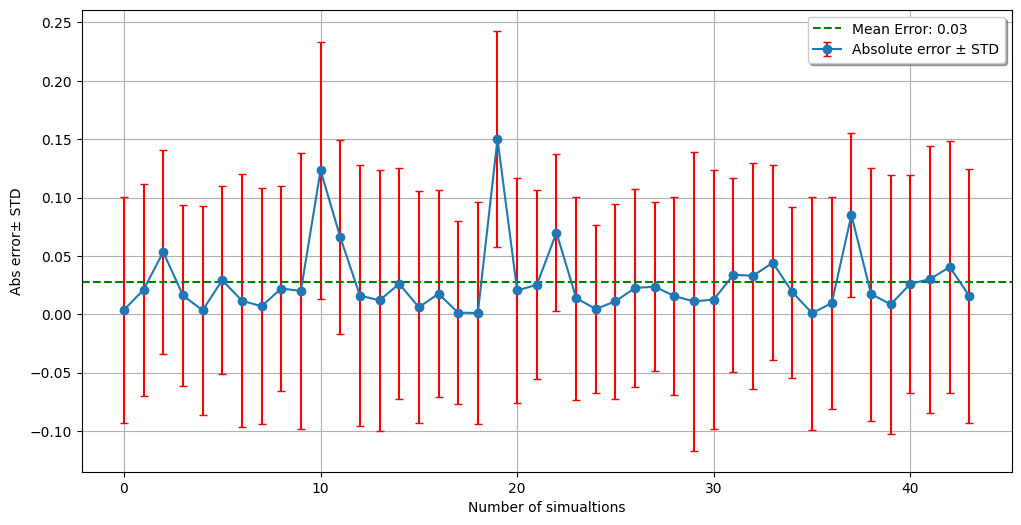

In [83]:
# Errorbar plot
x = np.arange(len(err_abs_set))  # the number of test simualtions
y = err_abs_set                  # absolute error on the test set
uncertainity = STD_val.flatten()         # std of MEAN_val
mean_val = np.mean(err_abs_set)
plt.figure(figsize=(12, 6))
plt.grid(True)

# Creazione del grafico con barre d'errore
plt.errorbar(x, y, yerr= uncertainity, fmt='o', ecolor='red', 
             linestyle='-', capsize=3, label='Absolute error ± STD')
plt.axhline(mean_val, color = 'green', linestyle='--', label=f'Mean Error: {mean_val:.2f}')
plt.legend(loc='best', shadow=True, fontsize='medium')
plt.xlabel('Number of simualtions')
plt.ylabel('Abs error± STD')


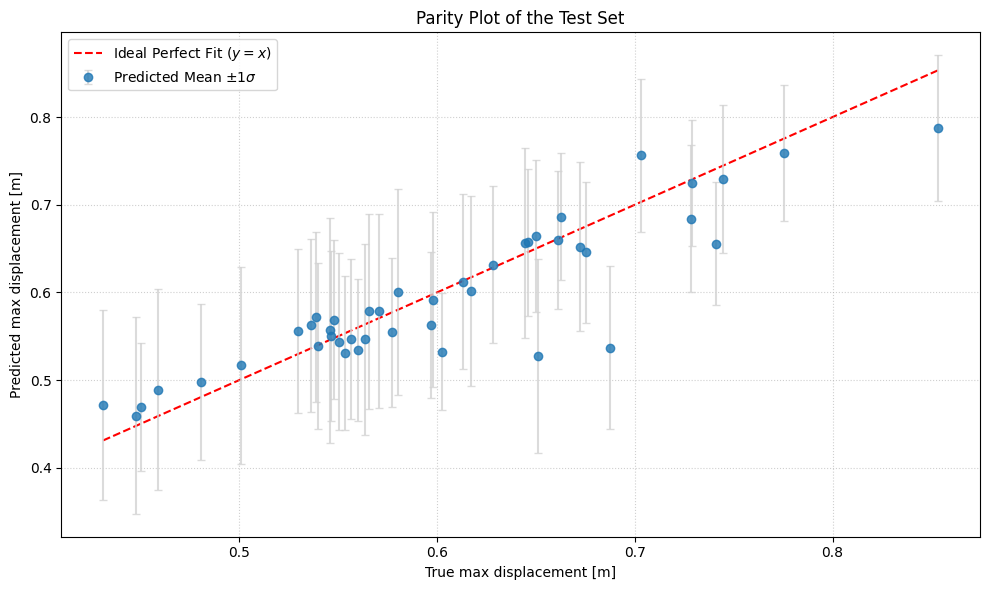

In [84]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Appiattiamo tutti gli array in vettori 1D per evitare problemi di dimensioni
x_true = TRUE_MAX_val.flatten()
y_pred = MEAN_val.flatten()
y_std = np.array(STD_val).flatten()

plt.figure(figsize=(10, 6))

# 2. Plot con Barre di Errore
plt.errorbar(
    x_true,
    y_pred,
    yerr=y_std,  # <-- Usa yerr=2*y_std se vuoi l'intervallo di confidenza al 95%
    fmt="o",  # Stile del punto
    color="#1f77b4",  # Colore del punto centrale
    ecolor="lightgray",  # Colore delle barre d'errore (grigio chiaro per non affollare)
    capsize=3,  # Trattini orizzontali in cima e in fondo alle barre
    alpha=0.8,
    label="Predicted Mean $\pm 1\sigma$",
)

# 3. Linea di Parità Ideale (y = x)
min_val = min(min(x_true), min(y_pred))
max_val = max(max(x_true), max(y_pred))
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    linewidth=1.5,
    zorder=0,
    label="Ideal Perfect Fit ($y=x$)",
)

# 4. Formattazione
plt.grid(True, linestyle=":", alpha=0.6)
plt.title("Parity Plot of the Test Set")
plt.xlabel("True max displacement [m]")
plt.ylabel("Predicted max displacement [m]")
plt.legend(loc="upper left")
plt.tight_layout()

plt.show()

### Optimization: fixing a base and looking for the best robot parameters



In [85]:
def new_loss_function(params_6d, y_target, x_base):

    #  param_names = ['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']
    #  params_6d contains the 6 values chosen by the BO (SCALED between 0,1)
    
    # Get the initialization of the full 9 vector (SCALED in between 0,1)
    full_v_scaled = np.zeros(9)
    
    # Put the base param in their place (x_base must have still values in 0,1)
    full_v_scaled[0] = x_base[0]
    full_v_scaled[2] = x_base[1]
    full_v_scaled[3] = x_base[2]
    
    # fill the remaining gaps
    indices_var = [1, 4, 5, 6, 7, 8]
    for i, val in enumerate(params_6d):
        full_v_scaled[indices_var[i]] = val

    #  Convert the params_list 
    params_vec_scaled = np.array(full_v_scaled).reshape(1, -1)
    
    #  Get back to the PHYSICAL values
    params_vec_phys = scaler_x_min.inverse_transform(params_vec_scaled).flatten()

    # compute the max displacement
    max_x, _, _, _ = simulate_peak_joint_position(params_vec_phys)

    # distance between target and maximum dispalcement from EOM
    eps = 1e-6
    d = np.abs(y_target - max_x) 

    return np.log10(d + eps)

In [86]:
# Base to choose: --> this reduces our search search_space_s from 9D to 6D 

# base found in the first BO: N.B it's a vector that is scaled
x_best_s = x_best_s.reshape(-1,1)
x_base = [x_best_s[0].item(), x_best_s[2].item(), x_best_s[3].item()]

x_base

# if we wanted to change base: 

[0.9311964877735821, 0.02800867183472567, 0.5037162456810012]

In [87]:
''' # if we wanted to change base: 

# Ordine: ['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']
valori_reali_base = np.zeros((1, 9)) 

valori_reali_base[0, 0] = 50000.0  # Kb reale
valori_reali_base[0, 2] = 60.0     # Mb reale
valori_reali_base[0, 3] = 0.5      # hb reale

# Trasformiamo i valori reali in valori scalati
valori_scalati_base = scaler_x_min.transform(valori_reali_base).flatten()

# Estraiamo i 3 che ci servono per x_base
x_base = [valori_scalati_base[0], valori_scalati_base[2], valori_scalati_base[3]]

print(f"I tuoi valori reali scalati sono: {x_base}") '''

' # if we wanted to change base: \n\n# Ordine: [\'Kb\', \'Kr\', \'Mb\', \'hb\', \'hr\', \'f0\', \'f1\', \'A_sin\', \'x_r_start\']\nvalori_reali_base = np.zeros((1, 9)) \n\nvalori_reali_base[0, 0] = 50000.0  # Kb reale\nvalori_reali_base[0, 2] = 60.0     # Mb reale\nvalori_reali_base[0, 3] = 0.5      # hb reale\n\n# Trasformiamo i valori reali in valori scalati\nvalori_scalati_base = scaler_x_min.transform(valori_reali_base).flatten()\n\n# Estraiamo i 3 che ci servono per x_base\nx_base = [valori_scalati_base[0], valori_scalati_base[2], valori_scalati_base[3]]\n\nprint(f"I tuoi valori reali scalati sono: {x_base}") '

In [88]:
# we need to make a function of 1 argument and the other is just a constant
y_target = 1.3*max_disp_onedof
print(max_disp_onedof, y_target)
obj_with_target = lambda p: new_loss_function(p, y_target, x_base)

0.8062739667225174 1.0481561567392725


In [89]:

# data form the 1 BO that will change
x_data_6d = [[c[1], c[4], c[5], c[6], c[7], c[8]] for c in res.x_iters]
# y_data_new = [np.abs(y_target - val) for val in res.func_vals] #use this if the obj_fun is not log10
y_data_new = [np.log10(np.abs(y_target - val) + 1e-6) for val in res.func_vals] # use this if obj_fun is log10


# search space REDUCED
search_space_s_6D = [search_space_s[i] for i in [1, 4, 5, 6, 7, 8]]

print(search_space_s_6D)


[Real(low=0.0, high=1.0, prior='uniform', transform='normalize'), Real(low=0.0, high=1.0, prior='uniform', transform='normalize'), Real(low=0.0, high=1.0, prior='uniform', transform='normalize'), Real(low=0.0, high=1.0, prior='uniform', transform='normalize'), Real(low=0.0, high=1.0, prior='uniform', transform='normalize'), Real(low=0.0, high=1.0, prior='uniform', transform='normalize')]


In [90]:
from sklearn.base import clone

# Get the optimal kernel from BO of 9D space
old_kernel = res.models[-1].kernel_

# Get the parameters of the kernel
params = old_kernel.get_params() # this is a dictionary, hence it has a key and a value

print(params) #do params.keys() if u want to see the dict's keys only

# Get the key of the length_scales of Matern
# usually it is 'k1__k2__length_scale' 
ls_key = [k for k in params.keys() if 'length_scale' in k and 'bounds' not in k][0]
old_ls = np.array(params[ls_key])

#  Get the variables that WILL CHANGE in the next BO
indices_var = [1, 4, 5, 6, 7, 8]
new_ls = old_ls[indices_var]

print(f"Old LS (9D): {old_ls}")
print(f"New LS (6D): {new_ls}")

{'k1': 0.846**2 * Matern(length_scale=[1.54, 1.15, 0.665, 4.81, 0.236, 14.8, 2.03, 1.53, 1.6], nu=2.5), 'k2': WhiteKernel(noise_level=0.0001), 'k1__k1': 0.846**2, 'k1__k2': Matern(length_scale=[1.54, 1.15, 0.665, 4.81, 0.236, 14.8, 2.03, 1.53, 1.6], nu=2.5), 'k1__k1__constant_value': np.float64(0.7150539195015557), 'k1__k1__constant_value_bounds': (0.001, 100000.0), 'k1__k2__length_scale': array([ 1.54374945,  1.1543333 ,  0.66456111,  4.81369268,  0.23622484,
       14.75550998,  2.03490816,  1.52511229,  1.60025605]), 'k1__k2__length_scale_bounds': (0.001, 100000.0), 'k1__k2__nu': 2.5, 'k2__noise_level': np.float64(0.00010000000000000009), 'k2__noise_level_bounds': (1e-08, 0.0001)}
Old LS (9D): [ 1.54374945  1.1543333   0.66456111  4.81369268  0.23622484 14.75550998
  2.03490816  1.52511229  1.60025605]
New LS (6D): [ 1.1543333   0.23622484 14.75550998  2.03490816  1.52511229  1.60025605]


In [91]:
# Define the kernel of 6 dimension
# length_scale must have the same length as the variable indices (6)

fresh_kernel_6d = (
    C(params['k1__k1__constant_value'], (1e-3, 1e5)) * 
    Matern(length_scale=new_ls, nu=2.5, length_scale_bounds=(1e-3, 1e3)) + 
    W(noise_level=params['k2__noise_level'], noise_level_bounds=(1e-8, 1e-4)) # (1e-12, 1e-6)
)

In [92]:
# Given the dataset built in the BO  we want to fix a target to reach and trhough exploitation alone get the 
# max dispalcement such that it is identical to the target one

from sklearn.base import clone
'''
# Get the dataset from the  FIRST BO
x_data = res.x_iters  # Explored points (DATSET)
# y_data = res.func_vals # Values of the cost fuction (the max) corresponding to the point of the dataset

y_data_new = [np.abs(y_target - val) for val in res.func_vals]

# Recall the kernel of the first BO

last_model = res.models[-1]


# 1. Recupera i parametri ottimizzati dal vecchio modello
# last_model.kernel_ contiene i valori finali trovati dalla prima BO
params_ottimizzati = last_model.kernel_.get_params()

# 2. Crea un NUOVO kernel identico ma "pulito"
# Usiamo clone per assicurarci che sia un oggetto fresco con le proprietà giuste
new_kernel = clone(fresh_skopt_kernel) # Usa la definizione originale del kernel
new_kernel.set_params(**params_ottimizzati) # Imposta i valori ottimi trovati
'''

# Initialize the GPR with the new kernel object
gpr_second_stage = GaussianProcessRegressor(
    kernel= fresh_kernel_6d, 
    optimizer="fmin_l_bfgs_b", 
    normalize_y=True,
    random_state=my_seed
)


# We want to pass the the old point as dataset

res_2 = gp_minimize(
    obj_with_target,    # the new objective/cost function (allungamento massimo)
    search_space_s_6D,       # Search space
    base_estimator = gpr_second_stage, # the gpr of the previuos BO
    x0 = x_data_6d,          # Dataset of  obtained from the first BO
    y0 = y_data_new,          
    n_calls = 20,         # How many points i want the BO to get
    n_initial_points = 0, # Number of points to get datset and not acquire: 0 cuz we have already x0 and y0
    acq_func = "LCB",
    acq_optimizer = "sampling",  # <--- AGGIUNGI QUESTO: risolve l'AttributeError
    n_points = 10000,            # <--- OPZIONALE: aumenta il numero di campioni per l'ottimizzatore
    xi = 0.0001,      # exploitation only
    random_state = my_seed
)



In [93]:
# COMMENT about the result: this BO holds for 1 fixed base specifically. we could change the base parameters with eps (in the neighborhood) 
# and still accept the results with such surrogate function. However if we drastically change the base we have to perform again the whole BO!
# if we wanted to be base independent we just forget about the the reduced 6d space and run the Bo on the whole space!

In [94]:
res_2

          fun: -1.8175969465653314
            x: [0.21409283221216374, 0.03469097193609195, 0.2825879670077685, 0.35713649171953016, 0.7866073360442408, 0.35089894745738087]
    func_vals: [ 2.197e-01  2.155e-01 ... -8.288e-01 -3.272e-01]
      x_iters: [[0.4880783992405838, 0.8080499633648479, 0.5656174196105307, 0.297622498703944, 0.04669572050695326, 0.9906273994707964], [0.76979302818994, 0.494147452240976, 0.9289483920955794, 0.39545404434582043, 0.9739562968289602, 0.5244147153752402], [0.8133084127821292, 0.29226911595916166, 0.8161423599871884, 0.8280425662068116, 0.22157737172957775, 0.6448347016033117], [0.41166323884293854, 0.21219617531555707, 0.47665615445586007, 0.07761383660001488, 0.2350437815245347, 0.006553002681164101], [0.5522344268776633, 0.5420876988179222, 0.041758531294239905, 0.5248768399620131, 0.640142540514325, 0.8006581636464108], [0.2526322301523826, 0.2640911698548721, 0.549378417816072, 0.3773337872453969, 0.20372834798319445, 0.9154624989798452], [0.83

In [95]:
10**res_2.fun

np.float64(0.015219593514474189)

In [96]:
# Get the parameters from the BO
x2_best = np.array(res_2.x)

# Reconstruct the full 9D vector in order to use .inverse_transform
full_v_best_scaled = np.zeros(9)
full_v_best_scaled[0] = x_base[0]
full_v_best_scaled[2] = x_base[1]
full_v_best_scaled[3] = x_base[2]

indices_var = [1, 4, 5, 6, 7, 8]

for i, val in enumerate(x2_best):
    full_v_best_scaled[indices_var[i]] = val

# Transform the 9D vector into REAL values
x_full_real = scaler_x_min.inverse_transform(full_v_best_scaled.reshape(1, -1)).flatten() #we get the optimized vector in REAL values

In [97]:
d_best = res_2.fun

In [98]:
# Show the results

print(f'The distance wrt target is: {(10**d_best)} [m]') 

print("\n--- REAL OPTIMAL PARAMETERS (ALL 9) ---")
all_names = ['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']
for name, value in zip(all_names, x_full_real):
    # Also show if the parameters were fixed or optimized 
    status = "(FIXED)" if all_names.index(name) in [0, 2, 3] else "(OPTIMIZED)"
    print(f"{name:10}: {value:10.4f} {status}")

The distance wrt target is: 0.015219593514474189 [m]

--- REAL OPTIMAL PARAMETERS (ALL 9) ---
Kb        :  4658.8417 (FIXED)
Kr        :  1160.9575 (OPTIMIZED)
Mb        :    12.6442 (FIXED)
hb        :     0.2008 (FIXED)
hr        :     0.1363 (OPTIMIZED)
f0        :     0.0029 (OPTIMIZED)
f1        :     5.5012 (OPTIMIZED)
A_sin     :     0.1784 (OPTIMIZED)
x_r_start :     0.3702 (OPTIMIZED)


### Animation of the optimization part

In [99]:
# get the true solution for the animation

true_max_disp_target, y_signal_test_target, xb_target, xr_target = simulate_peak_joint_position(x_full_real)

In [100]:
from matplotlib.animation import FuncAnimation

'''
start_time = 0.0
end_time = 40.0

visual_step = int(0.004 / Ts)
# 2. Subsample the result arrays
t_plot = t[::visual_step]
xb_plot = xb_target[::visual_step]
xr_plot = xr_target[::visual_step]
disp_onedof_plot = disp_onedof[::visual_step]


# Find indices in t_plot
idx_start = np.abs(t_plot - start_time).argmin()
idx_end = np.abs(t_plot - end_time).argmin()

# Slice the data to the specific interval
t_window = t_plot[idx_start:idx_end]
xb_window = xb_plot[idx_start:idx_end]
xr_window = xr_plot[idx_start:idx_end]
disp_onedof_window = disp_onedof_plot[idx_start:idx_end]

# --- 2. Setup Figure ---
fig, ax = plt.subplots()
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-1, 1)
ax.set_aspect('equal')
ax.set_title(f'2DOF System: {start_time}s to {end_time}s')

wall_x = 0.0
L1 = 0
L2 = x_full_real[-1]
h = 0.3 # vertical line length

# -- create the graphical object as 'empty shells' ---
masses, = ax.plot([], [], 'o', ms=20, color='royalblue')
spring_line1, = ax.plot([], [], '-', color='gray', lw=1)
spring_line2, = ax.plot([], [], '-', color='red', lw=1)
time_template = 'Time = %.2fs'
time_text = ax.text(0.05, 0.9, '', transform=ax.transAxes)
# Fixed wall at x = xr_start and the time history is disp_onedof
# ax.axvline(x=x_best[-1]+max_disp_onedof, color='black', lw=3)
# ax.axvline(max_disp_onedof,  color='black', lw=3)
ax.plot([max_disp_onedof, max_disp_onedof], [-h, h], color='black', lw=3, label='Limit')
# Define the Y limits for the vertical line to span the plot height
y_limits = [-1, 1] 
# line fot the rellative displacement of the robot
moving_line, = ax.plot([], [], color='black', lw=2, linestyle='--', label='1DOF Ref') # you need the comma
# line for the absolute displacement of the robot
moving_line_abs, = ax.plot([], [], color='green', lw=2, linestyle='--', label='Abs_disp_robot')
x_fissa = y_target # Inserisci qui la coordinata X dove vuoi la linea
ax.plot([x_fissa, x_fissa], [-h, h], color='red', lw=2, linestyle='--', label='Riferimento Fisso')

# --- 3. Animation Functions ---

def init():
    masses.set_data([], [])
    spring_line1.set_data([], [])
    spring_line2.set_data([], [])
    time_text.set_text('')
    moving_line.set_data([],[]) # Placeholder for init
    moving_line_abs.set_data([],[]) # Placeholder for init

    return masses, spring_line1, spring_line2, time_text, moving_line, moving_line_abs

def update(frame):
    # CRITICAL: Use the windowed data here
    current_time = t_window[frame]
    curr_x1 = xb_window[frame] + L1 # displacement of the base
    relative_start_pos = x_best[-1] # relative start position
    curr_x2 = curr_x1 + xr_window[frame] # displacment of the base + relative displacement of the robot
    curr_x3 = xr_window[frame]  # relative displacement of the robot
    
    
    # Update the vertical line position
    moving_line.set_data([curr_x3, curr_x3],[-h,h])
    moving_line_abs.set_data([curr_x2, curr_x2],[-h,h]) 


    masses.set_data([curr_x1, curr_x2], [0, 0])
    spring_line1.set_data([curr_x1, curr_x2], [0, 0])
    spring_line2.set_data([wall_x, curr_x1], [0, 0])
    time_text.set_text(time_template % current_time)

    
    return masses, spring_line1, spring_line2, time_text, moving_line, moving_line_abs

# --- 4. Run Animation ---
# We use step=1 for a smooth windowed view, or keep 50 if it's too slow
step = 10 # 每隔 5 个点画一帧，跨度为 0.02s
# 物理跨度 = visual_step * step * Ts = 0.004 * 5 = 0.02s

# 为了匹配真实时间，interval 应该设为 20ms (即每秒 50 帧)
# 计算公式：interval = (visual_step * step) * 1000
# 如果你想要 1:1 真实时间感：
actual_interval = 40 #20

ani = FuncAnimation(
    fig,
    update,
    frames=range(0, len(t_window), step),
    init_func=init,
    interval=actual_interval,
    blit=True
)

from IPython.display import HTML
HTML(ani.to_jshtml())
'''


"\nstart_time = 0.0\nend_time = 40.0\n\nvisual_step = int(0.004 / Ts)\n# 2. Subsample the result arrays\nt_plot = t[::visual_step]\nxb_plot = xb_target[::visual_step]\nxr_plot = xr_target[::visual_step]\ndisp_onedof_plot = disp_onedof[::visual_step]\n\n\n# Find indices in t_plot\nidx_start = np.abs(t_plot - start_time).argmin()\nidx_end = np.abs(t_plot - end_time).argmin()\n\n# Slice the data to the specific interval\nt_window = t_plot[idx_start:idx_end]\nxb_window = xb_plot[idx_start:idx_end]\nxr_window = xr_plot[idx_start:idx_end]\ndisp_onedof_window = disp_onedof_plot[idx_start:idx_end]\n\n# --- 2. Setup Figure ---\nfig, ax = plt.subplots()\nax.set_xlim(-0.5, 2.5)\nax.set_ylim(-1, 1)\nax.set_aspect('equal')\nax.set_title(f'2DOF System: {start_time}s to {end_time}s')\n\nwall_x = 0.0\nL1 = 0\nL2 = x_full_real[-1]\nh = 0.3 # vertical line length\n\n# -- create the graphical object as 'empty shells' ---\nmasses, = ax.plot([], [], 'o', ms=20, color='royalblue')\nspring_line1, = ax.plot([

### Comparison on more targets

In [101]:
# Base set

Mb_set = x_full_real[2]
Kb_set = x_full_real[0]
hb_set = x_full_real[3]

In [102]:
import numpy as np
import pandas as pd
from skopt import gp_minimize
from skopt.learning import GaussianProcessRegressor
from skopt.learning.gaussian_process.kernels import Matern, ConstantKernel as C, WhiteKernel as W

# ==================== SETUP (fai questo UNA VOLTA, fuori dal loop) ====================

indices_var = [1, 4, 5, 6, 7, 8]  # Kr, hr, f0, f1, A_sin, x_r_start
search_space_s_6D = [search_space_s[i] for i in indices_var]

# base fissa scelta (già la hai da x_base o da p_base_test convertiti in scala 0-1)
p_base_test = {'Mb': Mb_set, 'hb': hb_set, 'Kb': Kb_set}
valori_reali_base = np.zeros((1, 9))
valori_reali_base[0, 0] = Kb_set
valori_reali_base[0, 2] = Mb_set
valori_reali_base[0, 3] = hb_set
valori_scalati_base = scaler_x_min.transform(valori_reali_base).flatten()
x_base = [valori_scalati_base[0], valori_scalati_base[2], valori_scalati_base[3]]

# Dataset iniziale (dalla prima BO 9D) proiettato in 6D — è indipendente dal target
x_data_6d = [[c[1], c[4], c[5], c[6], c[7], c[8]] for c in res.x_iters]

# Kernel 6D "caldo" costruito dagli iperparametri della prima BO — costruiscilo una sola volta
old_kernel = res.models[-1].kernel_
params_k = old_kernel.get_params()
ls_key = [k for k in params_k.keys() if 'length_scale' in k and 'bounds' not in k][0]
old_ls = np.array(params_k[ls_key])
new_ls = old_ls[indices_var]

fresh_kernel_6d = (
    C(params_k['k1__k1__constant_value'], (1e-3, 1e5)) *
    Matern(length_scale=new_ls, nu=2.5, length_scale_bounds=(1e-3, 1e3)) +
    W(noise_level=params_k['k2__noise_level'], noise_level_bounds=(1e-8, 1e-4))
)


# ==================== FUNZIONE RIUSABILE PER UN SINGOLO TARGET ====================

def new_loss_function(params_6d, y_target, x_base):
    full_v_scaled = np.zeros(9)
    full_v_scaled[0] = x_base[0]
    full_v_scaled[2] = x_base[1]
    full_v_scaled[3] = x_base[2]
    for i, val in enumerate(params_6d):
        full_v_scaled[indices_var[i]] = val
    params_vec_phys = scaler_x_min.inverse_transform(full_v_scaled.reshape(1, -1)).flatten()
    max_x, _, _, _ = simulate_peak_joint_position(params_vec_phys)
    eps = 1e-6
    d = np.abs(y_target - max_x)
    return np.log10(d + eps)


def solve_inverse_for_target(y_target, x_base, x_data_6d, res_func_vals, n_calls=15, seed=42):
    """
    Risolve il problema inverso (BO in 6D) per un singolo target di spostamento,
    riusando il dataset e il kernel già esplorati nella prima BO 9D.
    """
    y_data_new = [np.log10(np.abs(y_target - val) + 1e-6) for val in res_func_vals]
    
    obj_with_target = lambda p: new_loss_function(p, y_target, x_base)
    
    gpr_second_stage = GaussianProcessRegressor(
        kernel=fresh_kernel_6d,
        optimizer="fmin_l_bfgs_b",
        normalize_y=True,
        random_state=seed
    )
    
    res_2 = gp_minimize(
        obj_with_target,
        search_space_s_6D,
        base_estimator=gpr_second_stage,
        x0=x_data_6d,
        y0=y_data_new,
        n_calls=n_calls,
        n_initial_points=0,
        acq_func="LCB",
        acq_optimizer="sampling",
        n_points=10000,
        xi=0.0001,
        random_state=seed
    )
    
    x2_best = np.array(res_2.x)
    full_v_best_scaled = np.zeros(9)
    full_v_best_scaled[0] = x_base[0]
    full_v_best_scaled[2] = x_base[1]
    full_v_best_scaled[3] = x_base[2]
    for i, val in enumerate(x2_best):
        full_v_best_scaled[indices_var[i]] = val
    
    x_full_real = scaler_x_min.inverse_transform(full_v_best_scaled.reshape(1, -1)).flatten()
    
    # Valore vero ottenuto (ri-simula al punto ottimo, coerente col log10 della loss)
    achieved, _, _, _ = simulate_peak_joint_position(x_full_real)
    
    return x_full_real, achieved, res_2.fun


# ==================== TEST RAPIDO SU POCHI TARGET PRIMA DEL LOOP COMPLETO ====================

target_vec_test = np.arange(0.75, 1.5, 0.05)  # 15 target, per validare il costo/tempo prima di scalare

results = []
for i, y_target in enumerate(target_vec_test):
    x_full_real, achieved, dist_log = solve_inverse_for_target(
        y_target, x_base, x_data_6d, res.func_vals, n_calls=15
    )
    results.append({
        'target': y_target,
        'achieved': achieved,
        'error': abs(achieved - y_target),
        **{name: val for name, val in zip(param_names, x_full_real)}
    })
    print(f"[{i+1}/{len(target_vec_test)}] target={y_target:.4f}  achieved={achieved:.4f}  err={abs(achieved - y_target):.4f}")

df_sweep = pd.DataFrame(results)

[1/15] target=0.7500  achieved=0.7570  err=0.0070
[2/15] target=0.8000  achieved=0.7570  err=0.0430
[3/15] target=0.8500  achieved=0.7570  err=0.0930
[4/15] target=0.9000  achieved=1.0231  err=0.1231
[5/15] target=0.9500  achieved=1.0231  err=0.0731
[6/15] target=1.0000  achieved=1.0231  err=0.0231
[7/15] target=1.0500  achieved=1.0329  err=0.0171
[8/15] target=1.1000  achieved=1.0329  err=0.0671
[9/15] target=1.1500  achieved=1.0329  err=0.1171
[10/15] target=1.2000  achieved=1.0329  err=0.1671
[11/15] target=1.2500  achieved=1.0329  err=0.2171
[12/15] target=1.3000  achieved=1.0329  err=0.2671
[13/15] target=1.3500  achieved=1.0329  err=0.3171
[14/15] target=1.4000  achieved=1.0329  err=0.3671
[15/15] target=1.4500  achieved=1.0329  err=0.4171


In [103]:
target_vec = np.arange(0.75, 1.5, 0.002)  # 375 target

results_full = []
for i, y_target in enumerate(target_vec):
    x_full_real, achieved, dist_log = solve_inverse_for_target(
        y_target, x_base, x_data_6d, res.func_vals, n_calls=15
    )
    results_full.append({
        'target': y_target,
        'achieved': achieved,
        'error': abs(achieved - y_target),
        **{name: val for name, val in zip(param_names, x_full_real)}
    })
    if i % 20 == 0:
        print(f"[{i}/{len(target_vec)}] target={y_target:.4f}  achieved={achieved:.4f}")

df_sweep_full = pd.DataFrame(results_full)
df_sweep_full.to_csv("inverse_sweep_results.csv", index=False)

[0/375] target=0.7500  achieved=0.7570


KeyboardInterrupt: 

In [120]:
import numpy as np
from skopt import Optimizer

my_seed = 54

# 1. Inizializziamo l'ottimizzatore
opt = Optimizer(
    dimensions=search_space_s,
    base_estimator= gpr,
    acq_func="EI",
    acq_optimizer="lbfgs",
    random_state=my_seed,
)

n_calls = 150
n_initial_points = 40

# 2. Ciclo di ottimizzazione manuale
for i in range(n_calls):
    # Suggerisci il prossimo punto
    x = opt.ask()

    # Valuta la funzione obiettivo
    y = loss_function(x)

    # Riduci progressivamente xi man mano che le iterazioni avanzano
    # All'iterazione 40 xi sarà ~0.05, all'iterazione 150 scenderà a ~0.001
    progress = max(0, (i - n_initial_points) / (n_calls - n_initial_points))
    current_xi = 0.05 * (1 - progress) + 0.001 * progress

    # Aggiorna il modello con il nuovo punto e il nuovo xi
    opt.tell(x, y)
    opt.acq_func_kwargs = {"xi": current_xi}

In [121]:
res = opt.get_result()
res

          fun: -1.4304240275840314
            x: [1.0, 0.08632128353591148, 0.0, 0.0, 0.0, 0.0, 0.0, 0.9449592174300373, 1.0]
    func_vals: [-7.481e-01 -4.752e-01 ... -9.124e-01 -1.161e+00]
      x_iters: [[0.42018296714077397, 0.3632394969650857, 0.18487668776145175, 0.5182827281674763, 0.008605452008769278, 0.9689362067194864, 0.8013812560164612, 0.7573119886086547, 0.6714843018418241], [0.029657008824923177, 0.3915620299803316, 0.4047940389966349, 0.18963101438430258, 0.7671056444827395, 0.6167231453119083, 0.9262739639908839, 0.32512403410196816, 0.25315435234977307], [0.7202179185720076, 0.9969574629876883, 0.3078731722387296, 0.17198668168744194, 0.1753845256523198, 0.1638265921486909, 0.5850143765094814, 0.47353555736065, 0.46075695222601043], [0.23515400841256068, 0.8562171723045888, 0.4708937757422156, 0.05458343148805701, 0.9932570795485592, 0.19555638928867886, 0.7125248831952568, 0.8163899629267164, 0.4710572710728571], [0.26108617441106713, 0.44061904112717254, 0.2093829

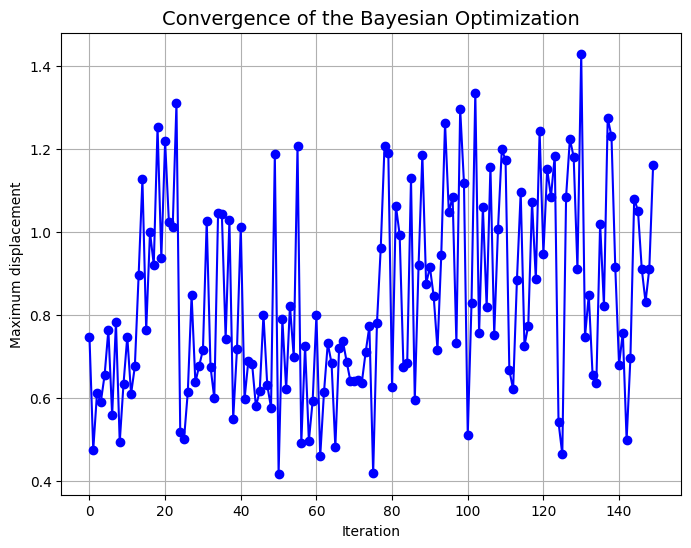

In [122]:
# PLOT CONVERGENCE RATE

plt.figure(figsize = (8,6))
plt.plot(np.abs(res.func_vals),marker = 'o', color = 'blue', label = 'Convergence plot')
plt.title('Convergence of the Bayesian Optimization', fontsize = 14)
plt.xlabel('Iteration')
plt.ylabel('Maximum displacement')
plt.grid(True)

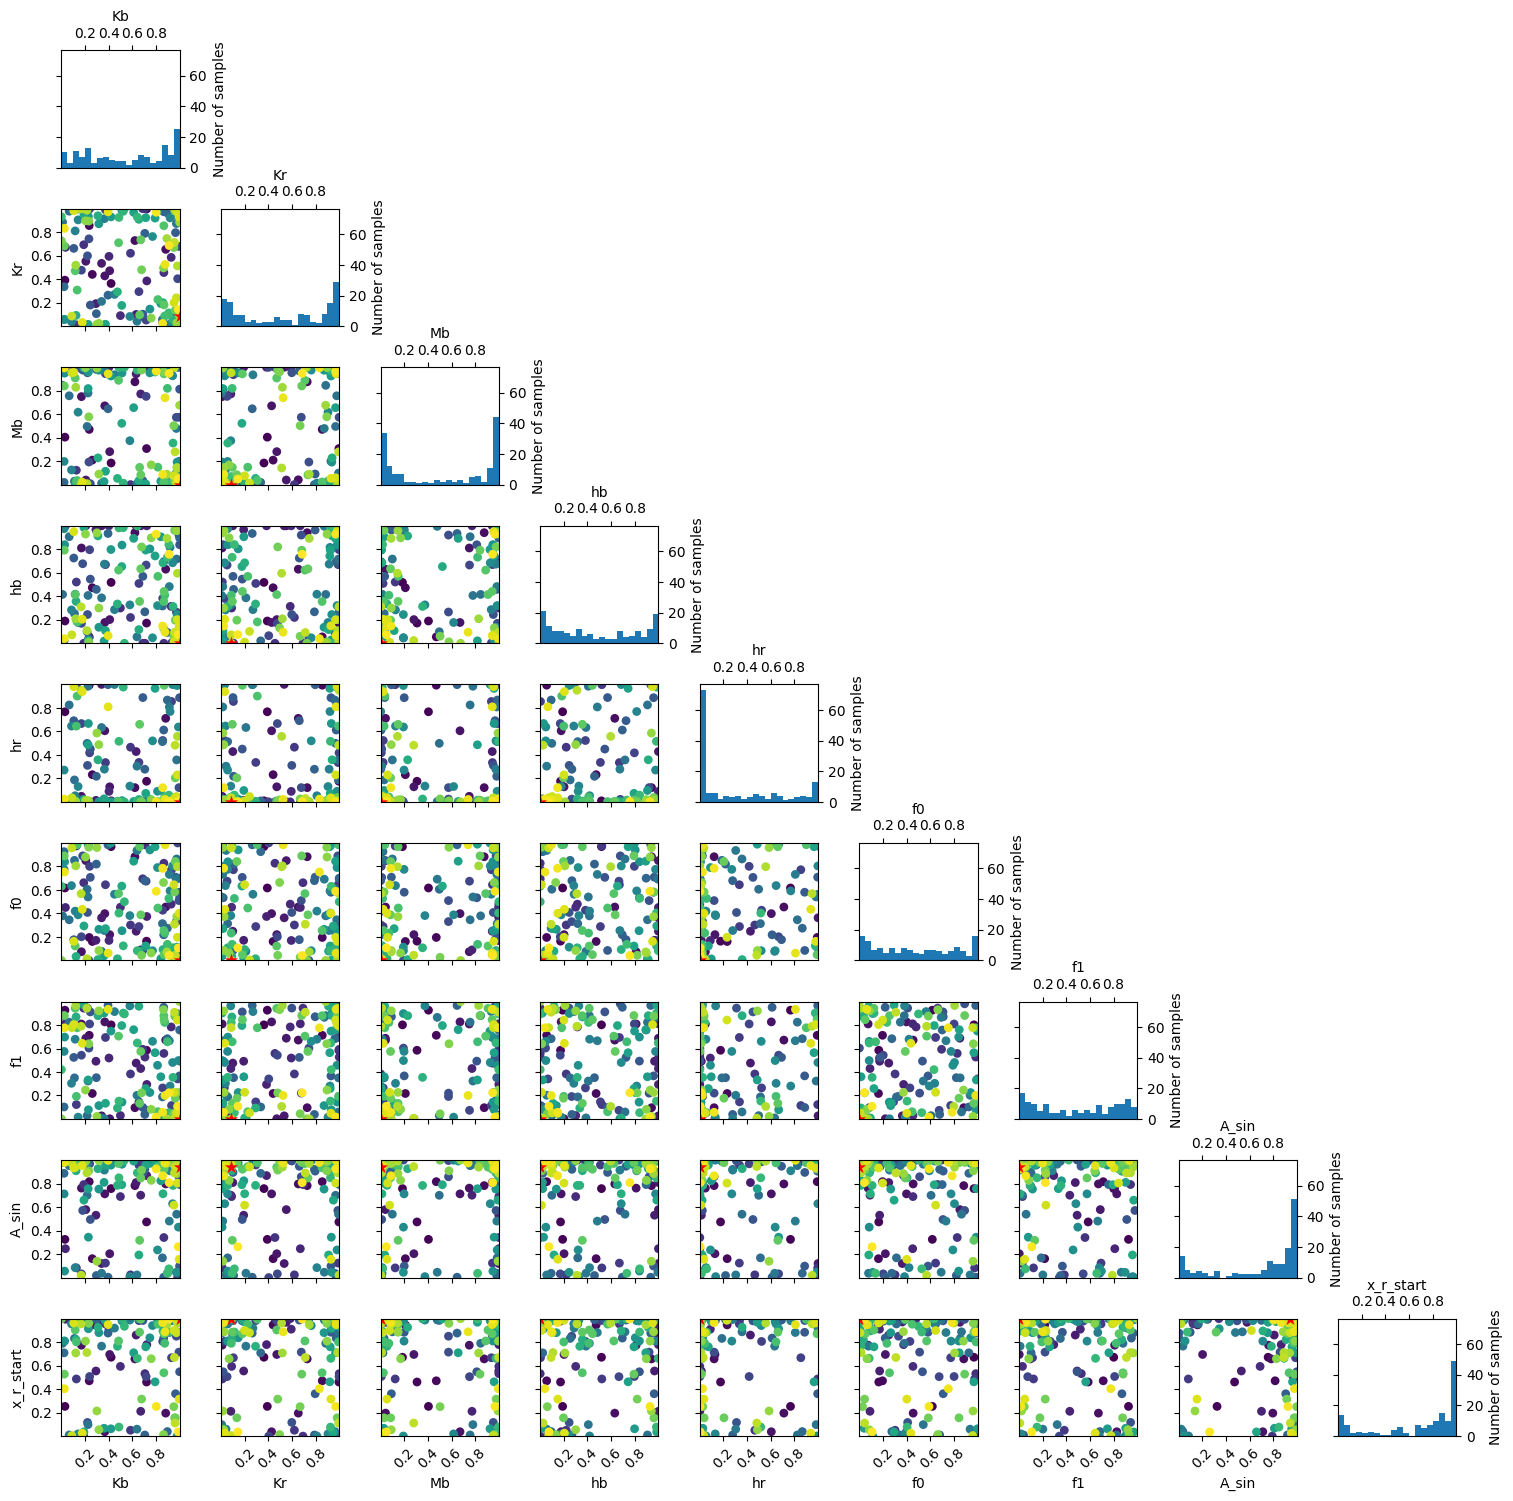

In [123]:
# Genera la Scatter Matrix completa per tutti i parametri dell'oggetto res
_ = plot_evaluations(res)
plt.show()

In [124]:
# WITH GP_HEDGE (20 min)
res = gp_minimize(
    loss_function,
    search_space_s,
    base_estimator=gpr,
    n_calls=200,
    n_initial_points=60,
    acq_func="gp_hedge",  # <-- Gestisce automaticamente l'equilibrio tra i picchi
    acq_optimizer="lbfgs",
    random_state=my_seed,
)

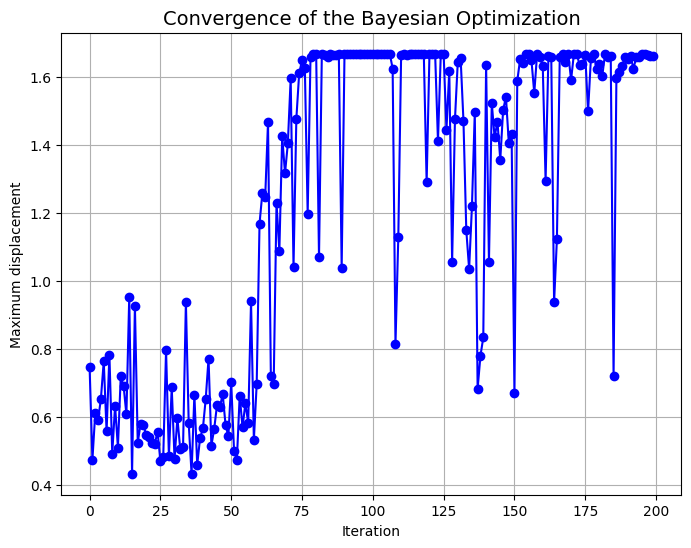

In [125]:
# PLOT CONVERGENCE RATE

plt.figure(figsize = (8,6))
plt.plot(np.abs(res.func_vals),marker = 'o', color = 'blue', label = 'Convergence plot')
plt.title('Convergence of the Bayesian Optimization', fontsize = 14)
plt.xlabel('Iteration')
plt.ylabel('Maximum displacement')
plt.grid(True)

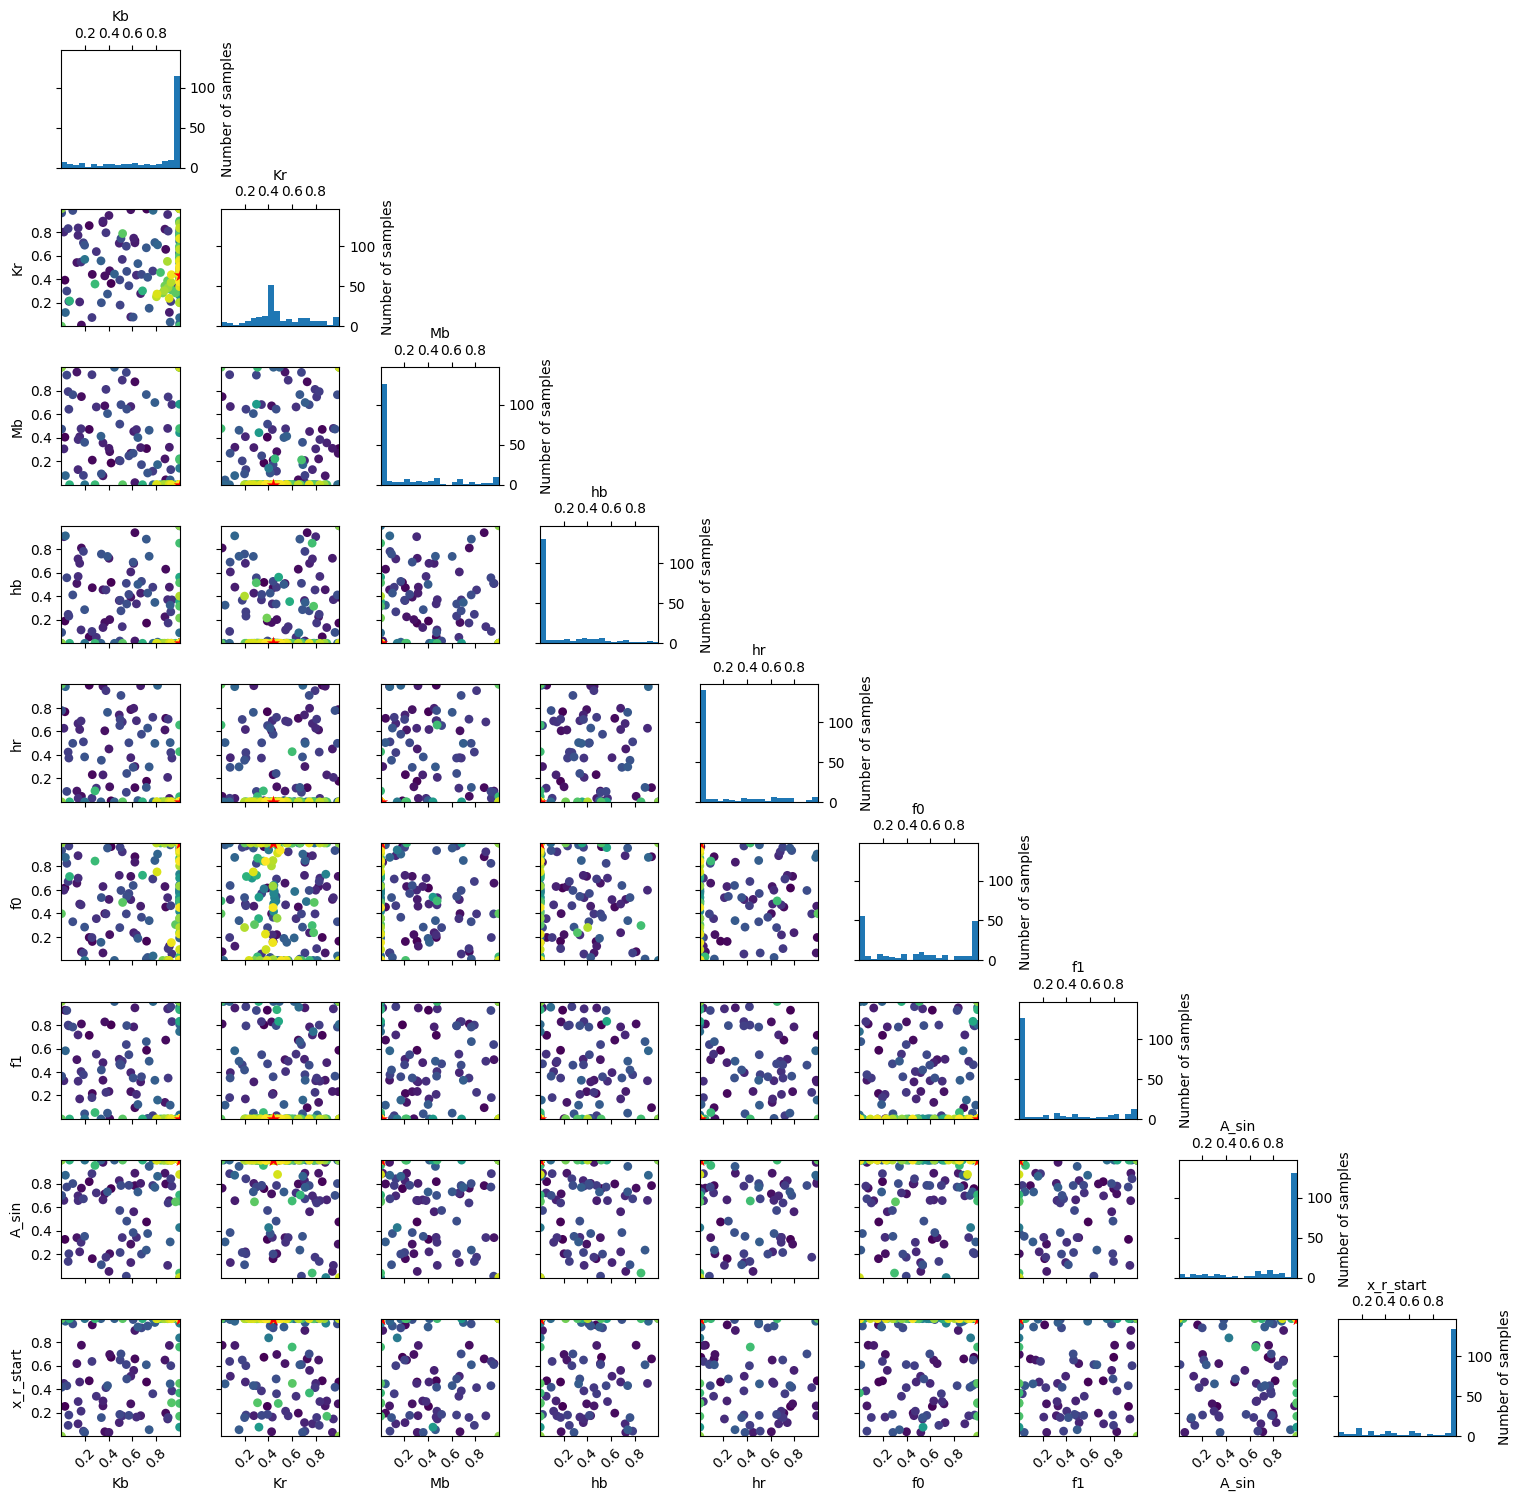

In [126]:
# Genera la Scatter Matrix completa per tutti i parametri dell'oggetto res
_ = plot_evaluations(res)
plt.show()

In [127]:
from skopt import Optimizer

opt = Optimizer(
    dimensions=search_space_s,
    base_estimator=gpr,  # gpr con n_restarts_optimizer=2 per volare in velocità
    acq_func="EI",  # UNA SOLA funzione!
    n_initial_points=60,
    acq_optimizer="lbfgs",
    random_state=my_seed,
)

n_calls = 200
n_initial_points = 60

for i in range(n_calls):
    x = opt.ask()
    y = loss_function(x)

    # Decadimento dinamico: parte esplorativo e diventa ultra-avidamente focalizzato
    progress = max(0, (i - n_initial_points) / (n_calls - n_initial_points))
    current_xi = 0.05 * (1 - progress) + 0.0001 * progress

    opt.tell(x, y)
    opt.acq_func_kwargs = {"xi": current_xi}

res_to_try = opt.get_result()

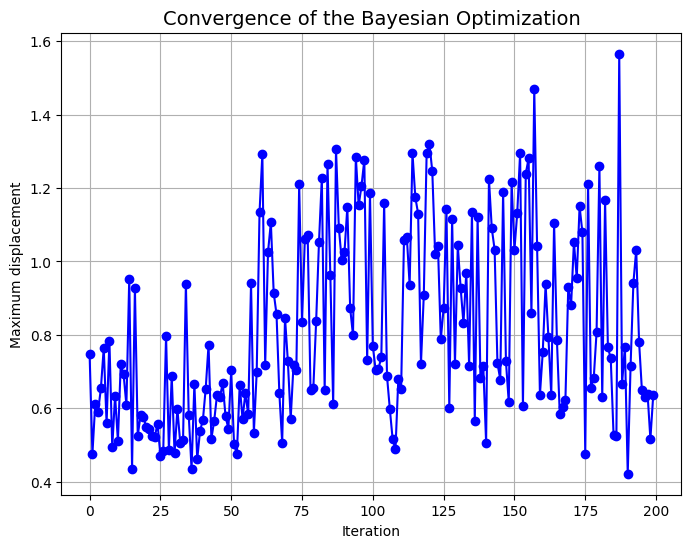

In [128]:
# PLOT CONVERGENCE RATE

plt.figure(figsize = (8,6))
plt.plot(np.abs(res_to_try.func_vals),marker = 'o', color = 'blue', label = 'Convergence plot')
plt.title('Convergence of the Bayesian Optimization', fontsize = 14)
plt.xlabel('Iteration')
plt.ylabel('Maximum displacement')
plt.grid(True)

In [129]:
import numpy as np
from scipy.optimize import minimize

# 1. Recuperiamo il Processo Gaussiano addestrato
trained_gp = res.models[-1]

# 2. DEFINISCI IL TUO SETUP INVERSO
# Inserisci i valori fissi dei primi 3 parametri (es. Kb, Kr, Mb)
fixed_3_params = [0.5, 0.2, 0.1]

# Inserisci lo spostamento target che desideri ottenere
y_target = 1.30

# 3. Limiti (bounds) per i 6 parametri liberi (dal 4° al 9° parametro)
bounds_6_free = [(b.low, b.high) for b in search_space_s[3:]]

# Punto di partenza x0 al centro dell'intervallo per i 6 parametri liberi
x0_free = [(b[0] + b[1]) / 2 for b in bounds_6_free]


# 4. Definiamo la funzione obiettivo dell'inversione
def inverse_objective(free_params):
    # Ricostruiamo il vettore completo a 9D
    full_x = np.array(fixed_3_params + list(free_params)).reshape(1, -1)

    # Interroghiamo il GP (istantaneo, richiede < 1 ms!)
    y_pred = trained_gp.predict(full_x)[0]

    # Vogliamo che y_pred sia il più vicino possibile a y_target
    # (Prendiamo il valore assoluto poiché la loss originale usava np.abs)
    return (np.abs(y_pred) - y_target) ** 2


# 5. RISOLVIAMO IL PROBLEMA INVERSO IN UN FRAZIONE DI SECONDO
res_inverse = minimize(
    inverse_objective,
    x0=x0_free,
    bounds=bounds_6_free,
    method="L-BFGS-B",
)

# 6. Risultati
best_6_params = res_inverse.x
full_solution = fixed_3_params + list(best_6_params)

x_eval = np.array(full_solution).reshape(1, -1)
predicted_y = trained_gp.predict(x_eval)[0]

print("=== RISULTATO PROBLEMA INVERSO ===")
print(f"I 6 parametri liberi ottimali: {best_6_params}")
print(f"Target richiesto: {y_target}")
print(f"Predizione del GP con questa configurazione: {np.abs(predicted_y):.4f}")

=== RISULTATO PROBLEMA INVERSO ===
I 6 parametri liberi ottimali: [0.         0.         0.50439875 0.07123357 1.         1.        ]
Target richiesto: 1.3
Predizione del GP con questa configurazione: 1.3000


In [130]:
best_6_params

array([0.        , 0.        , 0.50439875, 0.07123357, 1.        ,
       1.        ])

In [131]:
# ==============================================================================
# 1. CONFIGURAZIONE VALORI E LIMITI REALI
# ==============================================================================

# A. Inserisci qui i LIMITI REALI (min, max) usati per definire lo spazio di ricerca
# (Sostituisci questi valori di esempio con quelli reali dei tuoi 9 parametri)
real_bounds_all = [
    (100.0, 1000.0),  # Param 1: Kb (min, max reali)
    (0.05, 0.5),  # Param 2: Kr
    (10.0, 200.0),  # Param 3: Mb
    (0.01, 0.1),  # Param 4: hb
    (0.01, 0.1),  # Param 5: hr
    (1.0, 20.0),  # Param 6: f0
    (1.0, 50.0),  # Param 7: f1
    (0.1, 2.0),  # Param 8: A_sin
    (0.0, 1.0),  # Param 9: x_r_start
]

# B. Inserisci i VALORI REALI/FISICI della base (i primi 3 parametri)
fixed_3_real = [500.0, 0.25, 100.0]  # from brute force Kb = 4889.1206, hb = 0.1, Mb = 10.0000


# Funzione Helper: da REALE a SCALATO [0, 1]
def scale_val(val, v_min, v_max):
    return (val - v_min) / (v_max - v_min)


# Funzione Helper: da SCALATO [0, 1] a REALE
def unscale_val(val_scaled, v_min, v_max):
    return val_scaled * (v_max - v_min) + v_min


# Scaliamo automaticamente i primi 3 parametri per il GP
fixed_3_params = [
    scale_val(fixed_3_real[i], real_bounds_all[i][0], real_bounds_all[i][1])
    for i in range(3)
]

print("=== CONVERSIONE BASE INGRESSO ===")
print(f"Valori REALI inseriti:  {fixed_3_real}")
print(f"Valori SCALATI per GP:  {np.round(fixed_3_params, 4)}\n")

=== CONVERSIONE BASE INGRESSO ===
Valori REALI inseriti:  [500.0, 0.25, 100.0]
Valori SCALATI per GP:  [0.4444 0.4444 0.4737]



Avvio ottimizzazione inversa per 375 target...
Ottimizzazione completata!
Errore medio assoluto sulle predizioni: 0.218291


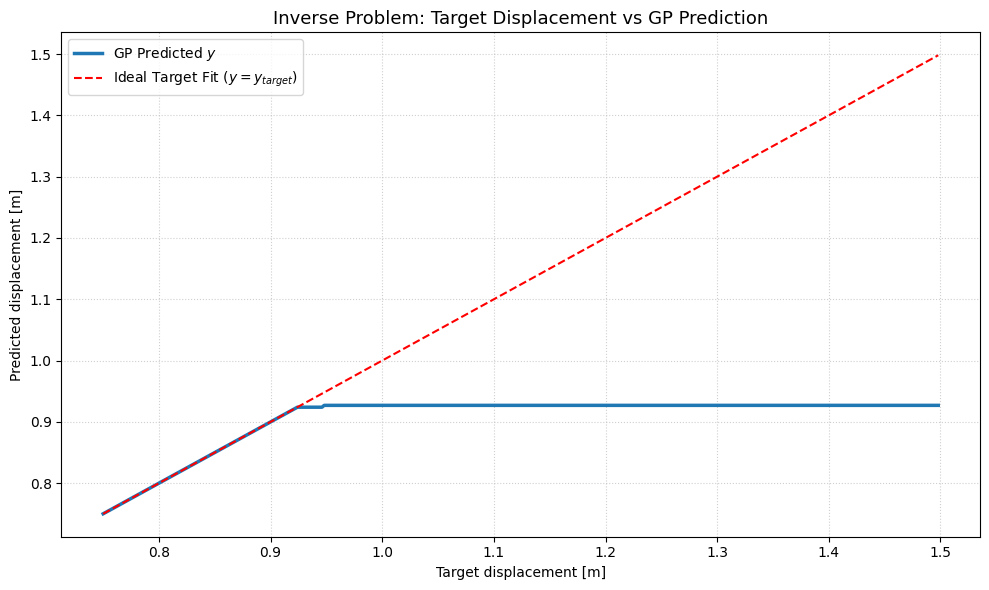

In [132]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. Recuperiamo il Processo Gaussiano addestrato
trained_gp = res.models[-1]

# 2. SETUP INVERSO E VETTORE TARGET
target_vec = np.arange(0.75, 1.5, 0.002)

bounds_6_free = [(b.low, b.high) for b in search_space_s[3:]]
x0_current = [(b[0] + b[1]) / 2 for b in bounds_6_free]  # Guess iniziale

# Liste per salvare i risultati
results = []
all_full_solutions = []

print(f"Avvio ottimizzazione inversa per {len(target_vec)} target...")

# 3. CICLO SUI TARGET
for y_target in target_vec:

    def inverse_objective(free_params):
        full_x = np.array(fixed_3_params + list(free_params)).reshape(1, -1)
        y_pred = trained_gp.predict(full_x)[0]
        return (np.abs(y_pred) - y_target) ** 2

    # Ottimizzazione locale L-BFGS-B
    res_inverse = minimize(
        inverse_objective,
        x0=x0_current,
        bounds=bounds_6_free,
        method="L-BFGS-B",
    )

    best_6_params = res_inverse.x
    full_solution = fixed_3_params + list(best_6_params)

    # Predizione verificata del GP
    x_eval = np.array(full_solution).reshape(1, -1)
    predicted_y = np.abs(trained_gp.predict(x_eval)[0])

    # Salvataggio dati
    results.append(
        {
            "target_y": y_target,
            "predicted_y": predicted_y,
            "error_abs": np.abs(predicted_y - y_target),
            "opt_success": res_inverse.success,
        }
    )

    all_full_solutions.append(full_solution)

    # WARM START: La soluzione attuale diventa il punto di partenza per il prossimo target!
    x0_current = best_6_params.copy()

# 4. SALVATAGGIO IN DATAFRAME E ARRAY NUMPY
df_results_inver = pd.DataFrame(results)

# Matrice NumPy di dimensioni (num_targets, 9) contenente i 9 parametri per ciascun target
matrix_parameters = np.array(all_full_solutions)

# Aggiungiamo i parametri al DataFrame per esportazione facilitata (es. CSV)
for i in range(9):
    df_results_inver[f"param_{i+1}"] = matrix_parameters[:, i]

print("Ottimizzazione completata!")
print(
    f"Errore medio assoluto sulle predizioni: {df_results_inver['error_abs'].mean():.6f}"
)

# 5. PLOT DEL CONFRONTO: TARGET VS PREDIZIONE
plt.figure(figsize=(10, 6))

# Curva Target reale vs Predizione
plt.plot(
    df_results_inver["target_y"],
    df_results_inver["predicted_y"],
    color="#1f77b4",
    linewidth=2.5,
    label="GP Predicted $y$",
)

# Bisettrice di riferimento ideale y = x
plt.plot(
    [target_vec.min(), target_vec.max()],
    [target_vec.min(), target_vec.max()],
    "r--",
    linewidth=1.5,
    label="Ideal Target Fit ($y = y_{target}$)",
)

plt.title("Inverse Problem: Target Displacement vs GP Prediction", fontsize=13)
plt.xlabel("Target displacement [m]")
plt.ylabel("Predicted displacement [m]")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

=== MAPPATURA INVERSA ===
Parametri FISSI (['Kb', 'Mb', 'hb']): {'Kb': 4889.1206, 'Mb': 10.0, 'hb': 0.1}
Parametri LIBERI (['Kr', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']): da ottimizzare

Avvio ottimizzazione inversa per 475 target...
Ottimizzazione completata!
Errore medio assoluto sulle predizioni: 0.000744


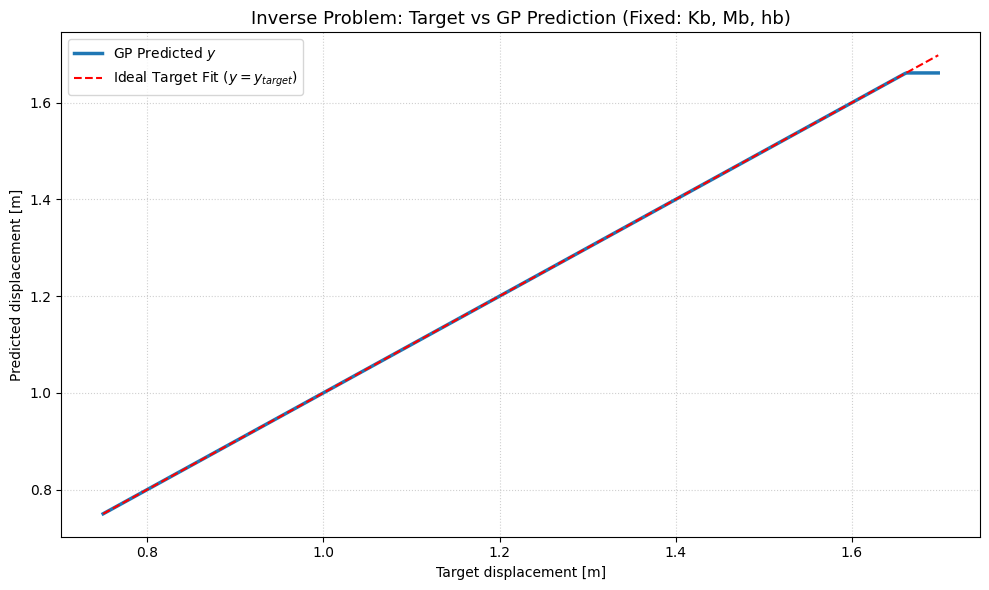

In [133]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# ==============================================================================
# 1. SETUP PARAMETRI E LIMITI REALI
# ==============================================================================
param_names = [
    "Kb",
    "Kr",
    "Mb",
    "hb",
    "hr",
    "f0",
    "f1",
    "A_sin",
    "x_r_start",
]
lb = np.array([100, 100, 10, 0.1, 0.1, 1e-4, 3, 0.1, 0.3])
ub = np.array([5000, 5000, 100, 0.3, 1.1, 1e-2, 10, 0.2, 0.5])

real_bounds_all = list(zip(lb, ub))


def scale_val(val, v_min, v_max):
    return (val - v_min) / (v_max - v_min)


def unscale_val(val_scaled, v_min, v_max):
    return val_scaled * (v_max - v_min) + v_min


# ==============================================================================
# 2. DEFINISCI I 3 PARAMETRI DI BASE DA FISSARE (VALORI REALI)
# ==============================================================================
fixed_real_dict = {"Kb": 4889.1206, "Mb": 10.0, "hb": 0.1}

# Individuazione automatica degli indici fisicamente fissati e di quelli liberi
fixed_indices = [param_names.index(p) for p in fixed_real_dict.keys()]
free_indices = [i for i in range(9) if i not in fixed_indices]

# Scaliamo i 3 valori fisso nel range [0, 1] per il GP
fixed_scaled_vals = [
    scale_val(
        fixed_real_dict[p],
        real_bounds_all[param_names.index(p)][0],
        real_bounds_all[param_names.index(p)][1],
    )
    for p in fixed_real_dict.keys()
]

print("=== MAPPATURA INVERSA ===")
print(f"Parametri FISSI ({list(fixed_real_dict.keys())}): {fixed_real_dict}")
print(
    f"Parametri LIBERI ({[param_names[i] for i in free_indices]}): da ottimizzare\n"
)

# ==============================================================================
# 3. CICLO DI OTTIMIZZAZIONE SUL VETTORE TARGET
# ==============================================================================
trained_gp = res.models[-1]
target_vec = np.arange(0.75, 1.7, 0.002)

# Bounds per i 6 parametri liberi nel GP
bounds_6_free = [(search_space_s[i].low, search_space_s[i].high) for i in free_indices]
x0_current = [(b[0] + b[1]) / 2 for b in bounds_6_free]

results = []
all_full_solutions_real = []

print(f"Avvio ottimizzazione inversa per {len(target_vec)} target...")

for y_target in target_vec:

    def inverse_objective(free_params):
        # Ricostruiamo il vettore 9D rispettando le posizioni usate nel GP
        full_x_scaled = np.zeros(9)
        full_x_scaled[fixed_indices] = fixed_scaled_vals
        full_x_scaled[free_indices] = free_params

        y_pred = trained_gp.predict(full_x_scaled.reshape(1, -1))[0]
        return (np.abs(y_pred) - y_target) ** 2

    res_inverse = minimize(
        inverse_objective,
        x0=x0_current,
        bounds=bounds_6_free,
        method="L-BFGS-B",
    )

    best_free_scaled = res_inverse.x

    # Ricostruzione della soluzione 9D completa (Scalata)
    full_sol_scaled = np.zeros(9)
    full_sol_scaled[fixed_indices] = fixed_scaled_vals
    full_sol_scaled[free_indices] = best_free_scaled

    # Riconversione in VALORI REALI per tutti e 9 i parametri
    full_sol_real = [
        unscale_val(
            full_sol_scaled[i], real_bounds_all[i][0], real_bounds_all[i][1]
        )
        for i in range(9)
    ]

    # Predizione verificata
    predicted_y = np.abs(
        trained_gp.predict(full_sol_scaled.reshape(1, -1))[0]
    )

    results.append(
        {
            "target_y": y_target,
            "predicted_y": predicted_y,
            "error_abs": np.abs(predicted_y - y_target),
        }
    )
    all_full_solutions_real.append(full_sol_real)

    # Warm Start per velocizzare
    x0_current = best_free_scaled.copy()

# ==============================================================================
# 4. SALVATAGGIO IN TABELLA PANDAS E CSV
# ==============================================================================
df_results = pd.DataFrame(results)
matrix_parameters_real = np.array(all_full_solutions_real)

for i, name in enumerate(param_names):
    df_results[f"{name}_real"] = matrix_parameters_real[:, i]

print("Ottimizzazione completata!")
print(
    f"Errore medio assoluto sulle predizioni: {df_results['error_abs'].mean():.6f}"
)

# Salva il file CSV
df_results.to_csv("risultati_inversi_Kb_Mb_hb.csv", index=False)

# ==============================================================================
# 5. PLOT
# ==============================================================================
plt.figure(figsize=(10, 6))
plt.plot(
    df_results["target_y"],
    df_results["predicted_y"],
    color="#1f77b4",
    linewidth=2.5,
    label="GP Predicted $y$",
)
plt.plot(
    [target_vec.min(), target_vec.max()],
    [target_vec.min(), target_vec.max()],
    "r--",
    linewidth=1.5,
    label="Ideal Target Fit ($y = y_{target}$)",
)

plt.title(
    "Inverse Problem: Target vs GP Prediction (Fixed: Kb, Mb, hb)", fontsize=13
)
plt.xlabel("Target displacement [m]")
plt.ylabel("Predicted displacement [m]")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

=== MAPPATURA INVERSA ===
Parametri FISSI (['Kb', 'Mb', 'hb']): {'Kb': 4889.1206, 'Mb': 10.0, 'hb': 0.1}
Parametri LIBERI (['Kr', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']): da ottimizzare

Avvio ottimizzazione inversa per 475 target...
Ottimizzazione completata!
Errore medio assoluto sulle predizioni: 0.000744
Incertezza media del GP (STD): 0.081953


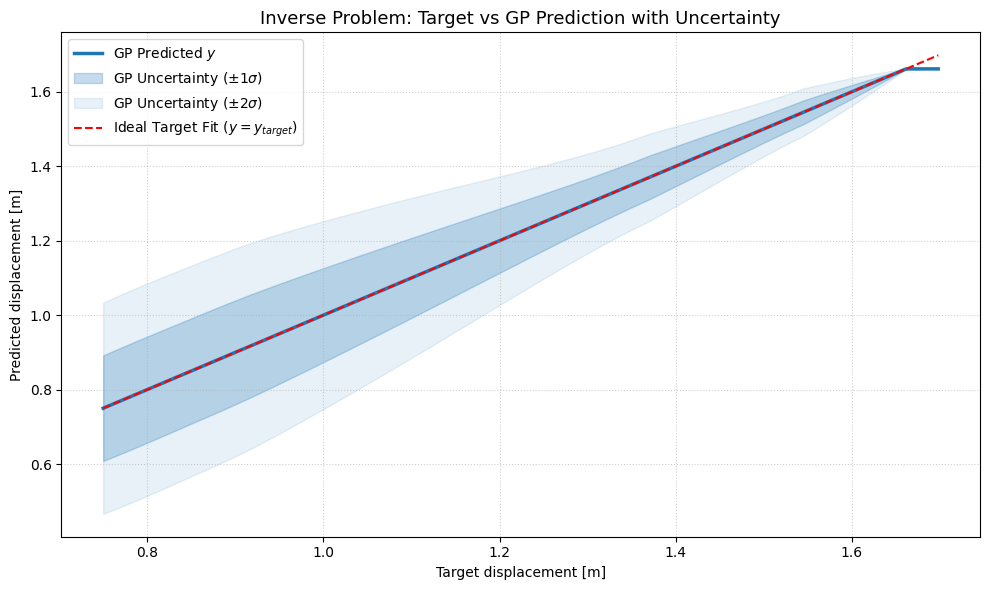

In [134]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# ==============================================================================
# 1. SETUP PARAMETRI E LIMITI REALI
# ==============================================================================
param_names = [
    "Kb",
    "Kr",
    "Mb",
    "hb",
    "hr",
    "f0",
    "f1",
    "A_sin",
    "x_r_start",
]
lb = np.array([100, 100, 10, 0.1, 0.1, 1e-4, 3, 0.1, 0.3])
ub = np.array([5000, 5000, 100, 0.3, 1.1, 1e-2, 10, 0.2, 0.5])

real_bounds_all = list(zip(lb, ub))


def scale_val(val, v_min, v_max):
    return (val - v_min) / (v_max - v_min)


def unscale_val(val_scaled, v_min, v_max):
    return val_scaled * (v_max - v_min) + v_min


# ==============================================================================
# 2. DEFINISCI I 3 PARAMETRI DI BASE DA FISSARE (VALORI REALI)
# ==============================================================================
fixed_real_dict = {"Kb": 4889.1206, "Mb": 10.0, "hb": 0.1}

fixed_indices = [param_names.index(p) for p in fixed_real_dict.keys()]
free_indices = [i for i in range(9) if i not in fixed_indices]

fixed_scaled_vals = [
    scale_val(
        fixed_real_dict[p],
        real_bounds_all[param_names.index(p)][0],
        real_bounds_all[param_names.index(p)][1],
    )
    for p in fixed_real_dict.keys()
]

print("=== MAPPATURA INVERSA ===")
print(f"Parametri FISSI ({list(fixed_real_dict.keys())}): {fixed_real_dict}")
print(
    f"Parametri LIBERI ({[param_names[i] for i in free_indices]}): da ottimizzare\n"
)

# ==============================================================================
# 3. CICLO DI OTTIMIZZAZIONE SUL VETTORE TARGET
# ==============================================================================
trained_gp = res.models[-1]
target_vec = np.arange(0.75, 1.7, 0.002)

bounds_6_free = [(search_space_s[i].low, search_space_s[i].high) for i in free_indices]
x0_current = [(b[0] + b[1]) / 2 for b in bounds_6_free]

results = []
all_full_solutions_real = []

print(f"Avvio ottimizzazione inversa per {len(target_vec)} target...")

for y_target in target_vec:

    def inverse_objective(free_params):
        full_x_scaled = np.zeros(9)
        full_x_scaled[fixed_indices] = fixed_scaled_vals
        full_x_scaled[free_indices] = free_params

        y_pred = trained_gp.predict(full_x_scaled.reshape(1, -1))[0]
        return (np.abs(y_pred) - y_target) ** 2

    res_inverse = minimize(
        inverse_objective,
        x0=x0_current,
        bounds=bounds_6_free,
        method="L-BFGS-B",
    )

    best_free_scaled = res_inverse.x

    # Ricostruzione della soluzione 9D completa (Scalata)
    full_sol_scaled = np.zeros(9)
    full_sol_scaled[fixed_indices] = fixed_scaled_vals
    full_sol_scaled[free_indices] = best_free_scaled

    # Riconversione in VALORI REALI
    full_sol_real = [
        unscale_val(
            full_sol_scaled[i], real_bounds_all[i][0], real_bounds_all[i][1]
        )
        for i in range(9)
    ]

    # PREDIZIONE DEL GP CON DEVIAZIONE STANDARD (return_std=True)
    y_pred_mean, y_pred_std = trained_gp.predict(
        full_sol_scaled.reshape(1, -1), return_std=True
    )

    predicted_y = np.abs(y_pred_mean[0])
    predicted_std = y_pred_std[0]

    results.append(
        {
            "target_y": y_target,
            "predicted_y": predicted_y,
            "std_y": predicted_std,  # <-- SALVATAGGIO DELLA STD
            "error_abs": np.abs(predicted_y - y_target),
        }
    )
    all_full_solutions_real.append(full_sol_real)

    x0_current = best_free_scaled.copy()

# ==============================================================================
# 4. SALVATAGGIO IN TABELLA PANDAS E CSV
# ==============================================================================
df_results = pd.DataFrame(results)
matrix_parameters_real = np.array(all_full_solutions_real)

for i, name in enumerate(param_names):
    df_results[f"{name}_real"] = matrix_parameters_real[:, i]

print("Ottimizzazione completata!")
print(
    f"Errore medio assoluto sulle predizioni: {df_results['error_abs'].mean():.6f}"
)
print(f"Incertezza media del GP (STD): {df_results['std_y'].mean():.6f}")

df_results.to_csv("risultati_inversi_Kb_Mb_hb_con_std.csv", index=False)

# ==============================================================================
# 5. PLOT CON BANDA DI INCERTEZZA (STD)
# ==============================================================================
plt.figure(figsize=(10, 6))

# 1. Curva Principale della Predizione GP
plt.plot(
    df_results["target_y"],
    df_results["predicted_y"],
    color="#1f77b4",
    linewidth=2.5,
    label="GP Predicted $y$",
)

# 2. Ombreggiatura Incertezza (1 Deviazione Standard: ~68% intervallo di confidenza)
plt.fill_between(
    df_results["target_y"],
    df_results["predicted_y"] - df_results["std_y"],
    df_results["predicted_y"] + df_results["std_y"],
    color="#1f77b4",
    alpha=0.25,
    label="GP Uncertainty ($\pm 1\sigma$)",
)

# 3. Ombreggiatura Incertezza Estesa (2 Deviazioni Standard: ~95% intervallo di confidenza)
plt.fill_between(
    df_results["target_y"],
    df_results["predicted_y"] - 2 * df_results["std_y"],
    df_results["predicted_y"] + 2 * df_results["std_y"],
    color="#1f77b4",
    alpha=0.10,
    label="GP Uncertainty ($\pm 2\sigma$)",
)

# 4. Bisettrice di riferimento ideale y = x
plt.plot(
    [target_vec.min(), target_vec.max()],
    [target_vec.min(), target_vec.max()],
    "r--",
    linewidth=1.5,
    label="Ideal Target Fit ($y = y_{target}$)",
)

plt.title(
    "Inverse Problem: Target vs GP Prediction with Uncertainty", fontsize=13
)
plt.xlabel("Target displacement [m]")
plt.ylabel("Predicted displacement [m]")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

=== MAPPATURA INVERSA ===
Parametri FISSI (['Kb', 'Mb', 'hb']): {'Kb': 4889.1206, 'Mb': 10.0, 'hb': 0.1}
Parametri LIBERI (['Kr', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']): da ottimizzare

Avvio ottimizzazione inversa per 475 target...
Ottimizzazione completata!
Errore medio assoluto sulle predizioni: 0.006679
Incertezza media del GP (STD): 0.048728


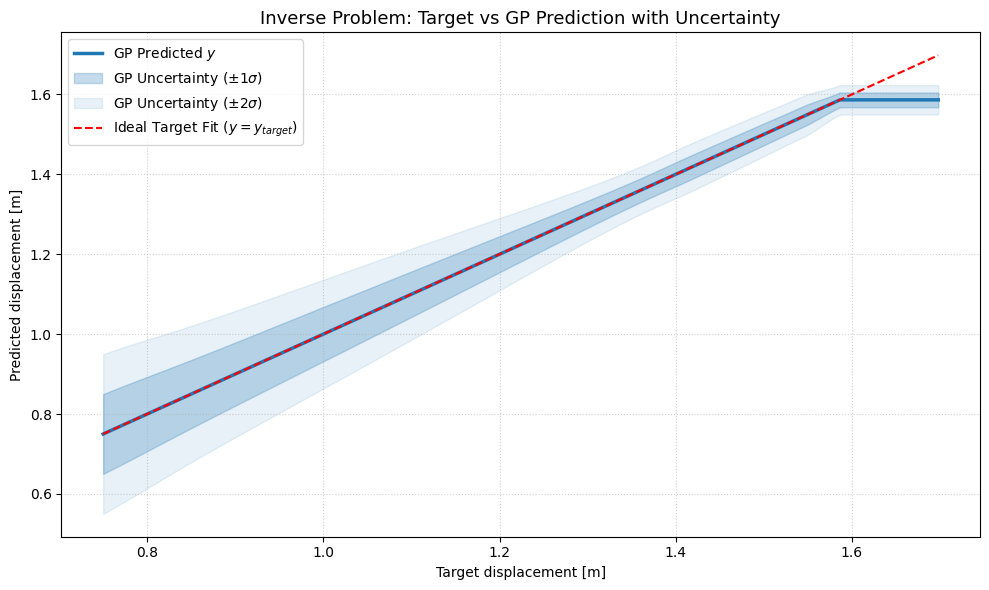

In [135]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# ==============================================================================
# 1. SETUP PARAMETRI E LIMITI REALI
# ==============================================================================
param_names = [
    "Kb",
    "Kr",
    "Mb",
    "hb",
    "hr",
    "f0",
    "f1",
    "A_sin",
    "x_r_start",
]
lb = np.array([100, 100, 10, 0.1, 0.1, 1e-4, 3, 0.1, 0.3])
ub = np.array([5000, 5000, 100, 0.3, 1.1, 1e-2, 10, 0.2, 0.5])

real_bounds_all = list(zip(lb, ub))


def scale_val(val, v_min, v_max):
    return (val - v_min) / (v_max - v_min)


def unscale_val(val_scaled, v_min, v_max):
    return val_scaled * (v_max - v_min) + v_min


# ==============================================================================
# 2. DEFINISCI I 3 PARAMETRI DI BASE DA FISSARE (VALORI REALI)
# ==============================================================================
fixed_real_dict = {"Kb": 4889.1206, "Mb": 10.0, "hb": 0.1}

fixed_indices = [param_names.index(p) for p in fixed_real_dict.keys()]
free_indices = [i for i in range(9) if i not in fixed_indices]

fixed_scaled_vals = [
    scale_val(
        fixed_real_dict[p],
        real_bounds_all[param_names.index(p)][0],
        real_bounds_all[param_names.index(p)][1],
    )
    for p in fixed_real_dict.keys()
]

print("=== MAPPATURA INVERSA ===")
print(f"Parametri FISSI ({list(fixed_real_dict.keys())}): {fixed_real_dict}")
print(
    f"Parametri LIBERI ({[param_names[i] for i in free_indices]}): da ottimizzare\n"
)

# ==============================================================================
# 3. CICLO DI OTTIMIZZAZIONE SUL VETTORE TARGET
# ==============================================================================
trained_gp = res_to_try.models[-1]
target_vec = np.arange(0.75, 1.7, 0.002)

bounds_6_free = [(search_space_s[i].low, search_space_s[i].high) for i in free_indices]
x0_current = [(b[0] + b[1]) / 2 for b in bounds_6_free]

results = []
all_full_solutions_real = []

print(f"Avvio ottimizzazione inversa per {len(target_vec)} target...")

for y_target in target_vec:

    def inverse_objective(free_params):
        full_x_scaled = np.zeros(9)
        full_x_scaled[fixed_indices] = fixed_scaled_vals
        full_x_scaled[free_indices] = free_params

        y_pred = trained_gp.predict(full_x_scaled.reshape(1, -1))[0]
        return (np.abs(y_pred) - y_target) ** 2

    res_inverse = minimize(
        inverse_objective,
        x0=x0_current,
        bounds=bounds_6_free,
        method="L-BFGS-B",
    )

    best_free_scaled = res_inverse.x

    # Ricostruzione della soluzione 9D completa (Scalata)
    full_sol_scaled = np.zeros(9)
    full_sol_scaled[fixed_indices] = fixed_scaled_vals
    full_sol_scaled[free_indices] = best_free_scaled

    # Riconversione in VALORI REALI
    full_sol_real = [
        unscale_val(
            full_sol_scaled[i], real_bounds_all[i][0], real_bounds_all[i][1]
        )
        for i in range(9)
    ]

    # PREDIZIONE DEL GP CON DEVIAZIONE STANDARD (return_std=True)
    y_pred_mean, y_pred_std = trained_gp.predict(
        full_sol_scaled.reshape(1, -1), return_std=True
    )

    predicted_y = np.abs(y_pred_mean[0])
    predicted_std = y_pred_std[0]

    results.append(
        {
            "target_y": y_target,
            "predicted_y": predicted_y,
            "std_y": predicted_std,  # <-- SALVATAGGIO DELLA STD
            "error_abs": np.abs(predicted_y - y_target),
        }
    )
    all_full_solutions_real.append(full_sol_real)

    x0_current = best_free_scaled.copy()

# ==============================================================================
# 4. SALVATAGGIO IN TABELLA PANDAS E CSV
# ==============================================================================
df_results = pd.DataFrame(results)
matrix_parameters_real = np.array(all_full_solutions_real)

for i, name in enumerate(param_names):
    df_results[f"{name}_real"] = matrix_parameters_real[:, i]

print("Ottimizzazione completata!")
print(
    f"Errore medio assoluto sulle predizioni: {df_results['error_abs'].mean():.6f}"
)
print(f"Incertezza media del GP (STD): {df_results['std_y'].mean():.6f}")

df_results.to_csv("risultati_inversi_Kb_Mb_hb_con_std.csv", index=False)

# ==============================================================================
# 5. PLOT CON BANDA DI INCERTEZZA (STD)
# ==============================================================================
plt.figure(figsize=(10, 6))

# 1. Curva Principale della Predizione GP
plt.plot(
    df_results["target_y"],
    df_results["predicted_y"],
    color="#1f77b4",
    linewidth=2.5,
    label="GP Predicted $y$",
)

# 2. Ombreggiatura Incertezza (1 Deviazione Standard: ~68% intervallo di confidenza)
plt.fill_between(
    df_results["target_y"],
    df_results["predicted_y"] - df_results["std_y"],
    df_results["predicted_y"] + df_results["std_y"],
    color="#1f77b4",
    alpha=0.25,
    label="GP Uncertainty ($\pm 1\sigma$)",
)

# 3. Ombreggiatura Incertezza Estesa (2 Deviazioni Standard: ~95% intervallo di confidenza)
plt.fill_between(
    df_results["target_y"],
    df_results["predicted_y"] - 2 * df_results["std_y"],
    df_results["predicted_y"] + 2 * df_results["std_y"],
    color="#1f77b4",
    alpha=0.10,
    label="GP Uncertainty ($\pm 2\sigma$)",
)

# 4. Bisettrice di riferimento ideale y = x
plt.plot(
    [target_vec.min(), target_vec.max()],
    [target_vec.min(), target_vec.max()],
    "r--",
    linewidth=1.5,
    label="Ideal Target Fit ($y = y_{target}$)",
)

plt.title(
    "Inverse Problem: Target vs GP Prediction with Uncertainty", fontsize=13
)
plt.xlabel("Target displacement [m]")
plt.ylabel("Predicted displacement [m]")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Errore medio assoluto ODE vs target: 0.048228 m
Errore medio assoluto GP  vs target: 0.006679 m


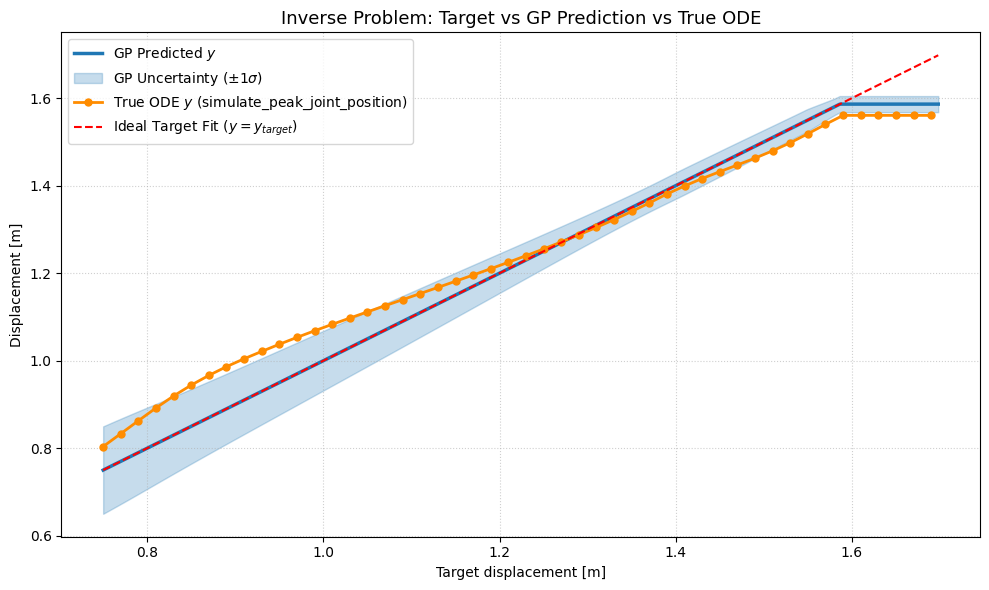

In [136]:
# ==============================================================================
# CONFRONTO: predizione del GP surrogato vs risultato della vera ODE
# (simulate_peak_joint_position), usando i 9 parametri reali trovati
# risolvendo il problema inverso per ogni target (df_results)
# ==============================================================================

# L'ODE e' costosa (Tsim/Ts = 800'000 punti per simulazione).
# subsample_step=1 -> valuta l'ODE su TUTTI i target (lento)
# subsample_step=N -> valuta l'ODE ogni N target (piu' veloce, ancora rappresentativo)
subsample_step = 10

idx_to_check = np.arange(0, len(df_results), subsample_step)

# Nomi delle colonne dei parametri reali, nell'ORDINE CORRETTO richiesto da
# simulate_peak_joint_position, cioe' l'ordine di param_names
real_param_cols = [f"{name}_real" for name in param_names]

true_ode_peaks = []
for idx in idx_to_check:
    params_vec = df_results.loc[idx, real_param_cols].values.astype(float)

    # Simulazione ODE vera con i 9 parametri (nell'ordine di param_names)
    max_disp_true, _, _, _ = simulate_peak_joint_position(params_vec)
    true_ode_peaks.append(np.abs(max_disp_true))

true_ode_peaks = np.array(true_ode_peaks)
target_sub = df_results["target_y"].values[idx_to_check]

# Errori di validazione
err_ode = np.abs(true_ode_peaks - target_sub)
print(f"Errore medio assoluto ODE vs target: {err_ode.mean():.6f} m")
print(f"Errore medio assoluto GP  vs target: {df_results['error_abs'].mean():.6f} m")

# ==============================================================================
# PLOT: GP surrogato vs ODE vera vs target (stesso stile dell'ultimo grafico)
# ==============================================================================
plt.figure(figsize=(10, 6))

# Curva della predizione del GP (come nell'ultimo grafico)
plt.plot(
    df_results["target_y"],
    df_results["predicted_y"],
    color="#1f77b4",
    linewidth=2.5,
    label="GP Predicted $y$",
)

# Banda di incertezza del GP (+-1 sigma)
plt.fill_between(
    df_results["target_y"],
    df_results["predicted_y"] - df_results["std_y"],
    df_results["predicted_y"] + df_results["std_y"],
    color="#1f77b4",
    alpha=0.25,
    label="GP Uncertainty ($\pm 1\sigma$)",
)

# Risultato della vera ODE per gli stessi 9 parametri
plt.plot(
    target_sub,
    true_ode_peaks,
    "o-",
    color="darkorange",
    linewidth=2,
    markersize=5,
    label="True ODE $y$ (simulate_peak_joint_position)",
)

# Bisettrice ideale y = target
plt.plot(
    [target_vec.min(), target_vec.max()],
    [target_vec.min(), target_vec.max()],
    "r--",
    linewidth=1.5,
    label="Ideal Target Fit ($y = y_{target}$)",
)

plt.title("Inverse Problem: Target vs GP Prediction vs True ODE", fontsize=13)
plt.xlabel("Target displacement [m]")
plt.ylabel("Displacement [m]")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


Errore relativo medio GP vs ODE vera: 3.8496 %
Errore relativo massimo GP vs ODE vera: 9.9816 %


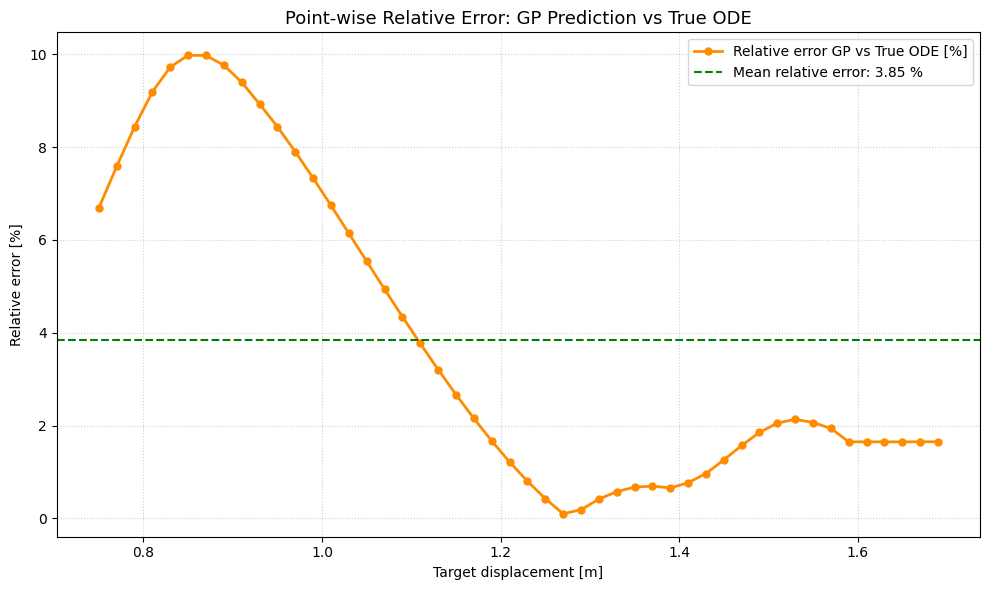

In [137]:
# ==============================================================================
# ERRORE RELATIVO PUNTO PER PUNTO tra la curva del GP e quella della vera ODE
# (le stesse due curve del grafico precedente, valutate sugli stessi target
# sottocampionati idx_to_check)
# ==============================================================================

# Predizione del GP sugli stessi indici sottocampionati usati per l'ODE
predicted_gp_sub = df_results["predicted_y"].values[idx_to_check]

# Errore relativo punto per punto (in %), rispetto al valore della vera ODE
rel_err_gp_vs_ode = np.abs(predicted_gp_sub - true_ode_peaks) / np.abs(true_ode_peaks) * 100

mean_rel_err_gp_vs_ode = rel_err_gp_vs_ode.mean()

print(f"Errore relativo medio GP vs ODE vera: {mean_rel_err_gp_vs_ode:.4f} %")
print(f"Errore relativo massimo GP vs ODE vera: {rel_err_gp_vs_ode.max():.4f} %")

# ==============================================================================
# PLOT: errore relativo punto per punto lungo il vettore target
# ==============================================================================
plt.figure(figsize=(10, 6))

plt.plot(
    target_sub,
    rel_err_gp_vs_ode,
    "o-",
    color="darkorange",
    linewidth=2,
    markersize=5,
    label="Relative error GP vs True ODE [%]",
)

plt.axhline(
    mean_rel_err_gp_vs_ode,
    color="green",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean relative error: {mean_rel_err_gp_vs_ode:.2f} %",
)

plt.title("Point-wise Relative Error: GP Prediction vs True ODE", fontsize=13)
plt.xlabel("Target displacement [m]")
plt.ylabel("Relative error [%]")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="best")
plt.tight_layout()
plt.show()
